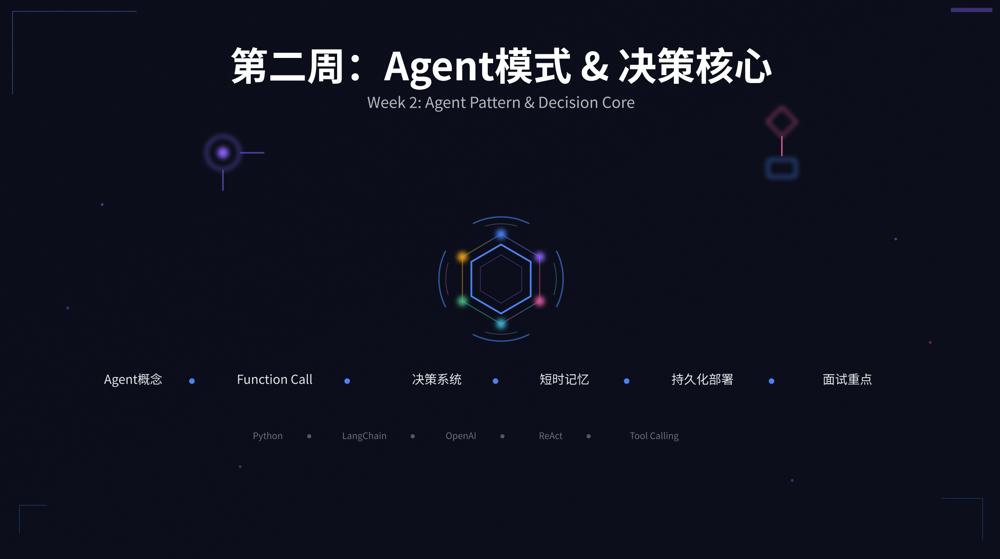

# 1.什么是Agent
这也是我面试经常会问的问题，你说你做Agent，那什么是agent呢，很少有人能回答明白

## 1.1 从LLM到单Agent

### 从LLM的问答，到端到端地去帮助人完成一个复杂的任务

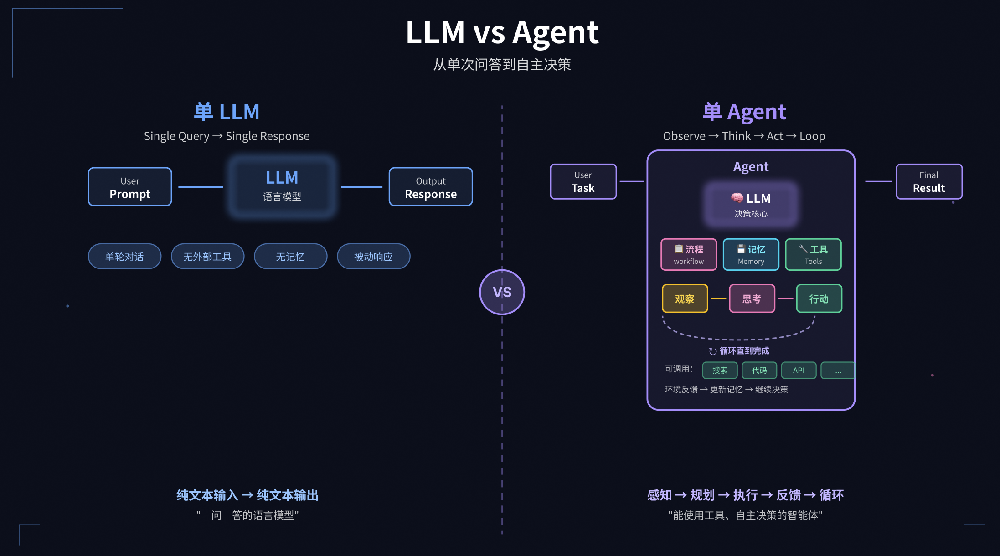

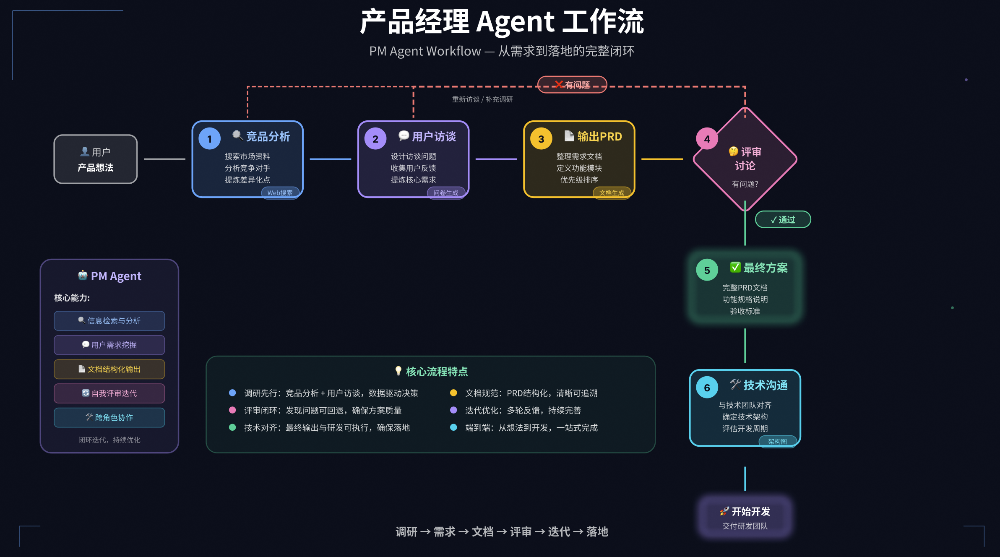

## 1.2 从单Agent 到 多Agent

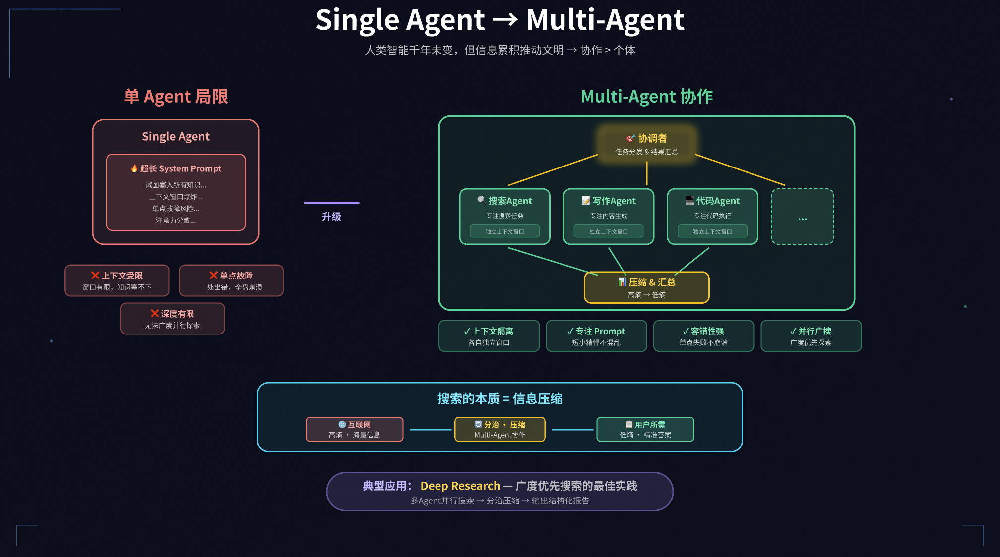

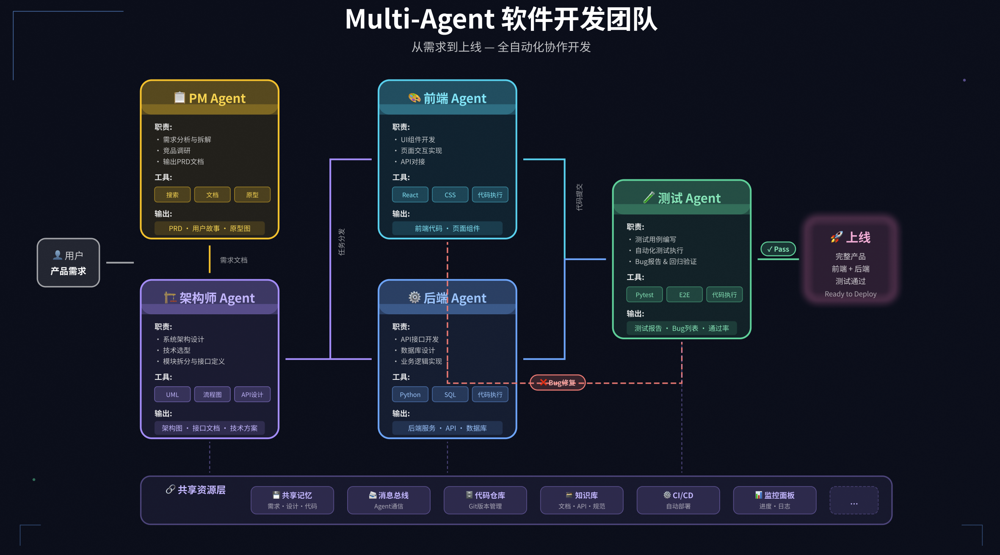

## 1.3 Agent架构解析

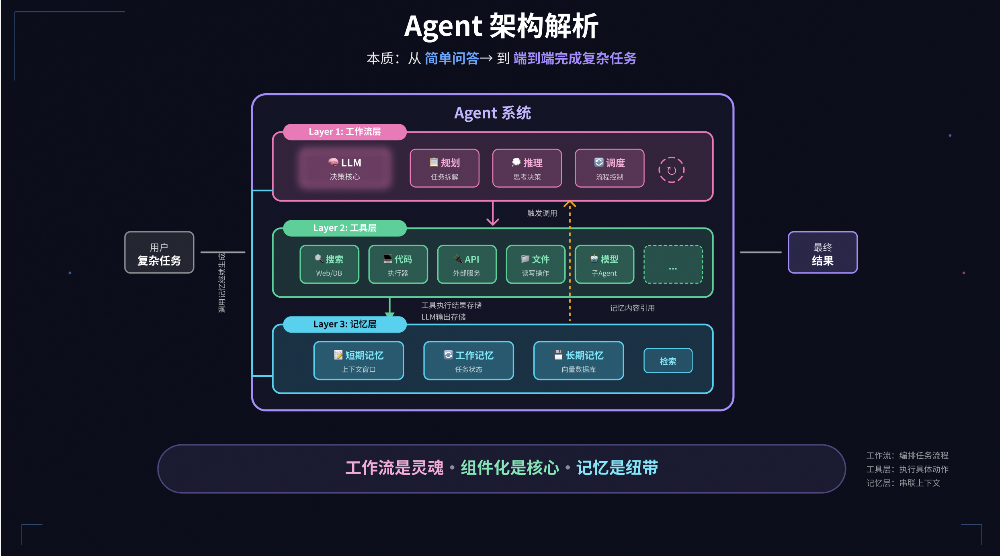

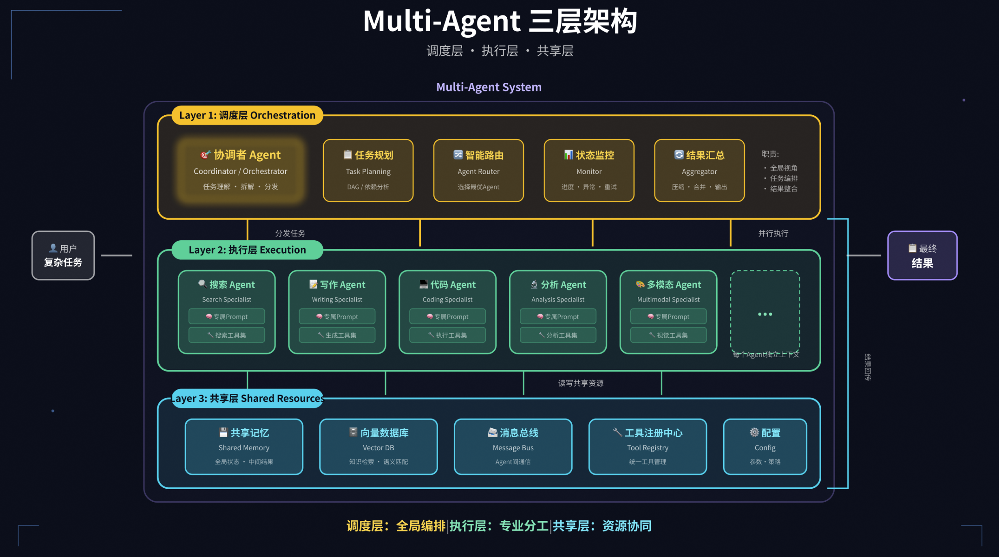

# 2.Function Call深度理解

- 2.0 Fc的理解
- 2.1 单个工具的fc
- 2.2 多个工具的fc
- 2.3 多轮链式工具的fc
- 2.4 单轮多个工具并行的fc

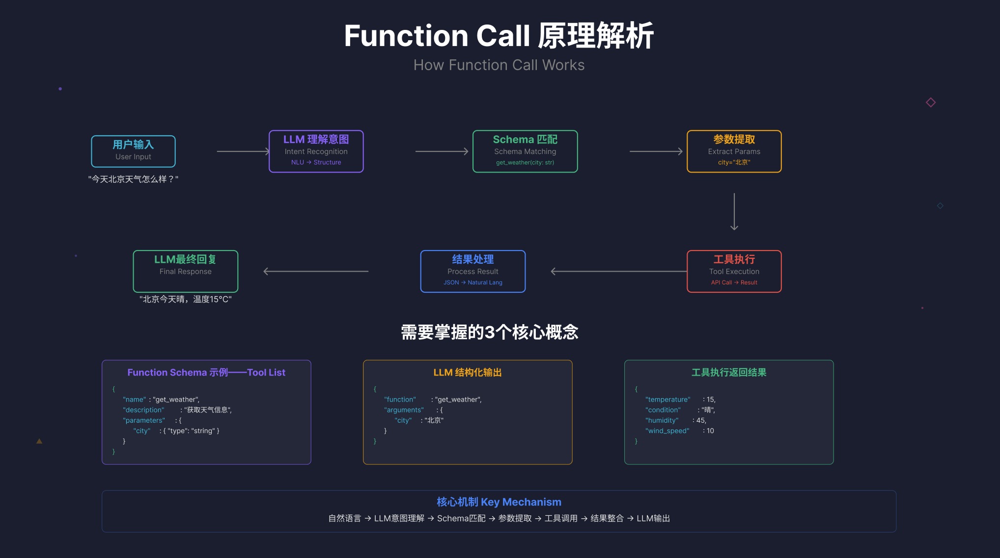

## 2.1 单个工具调用

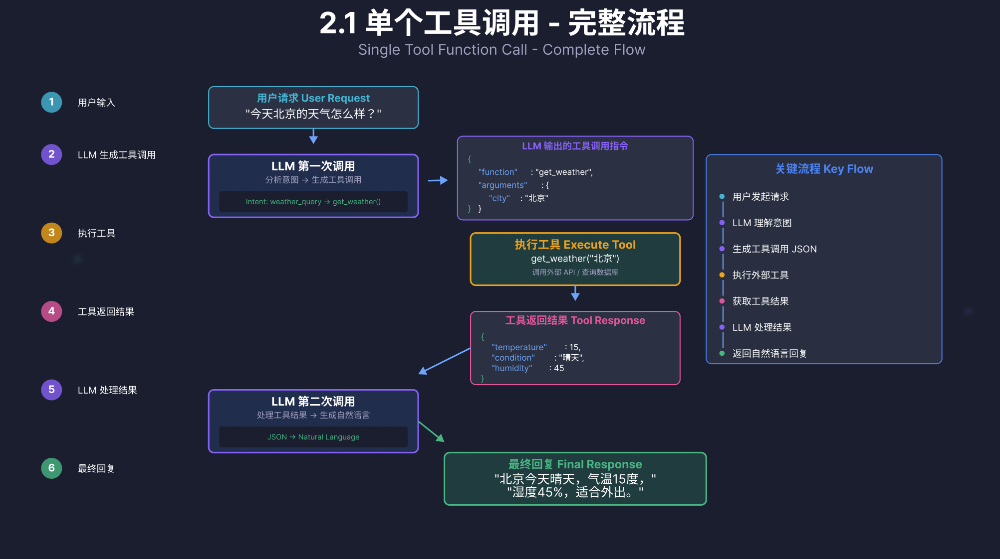

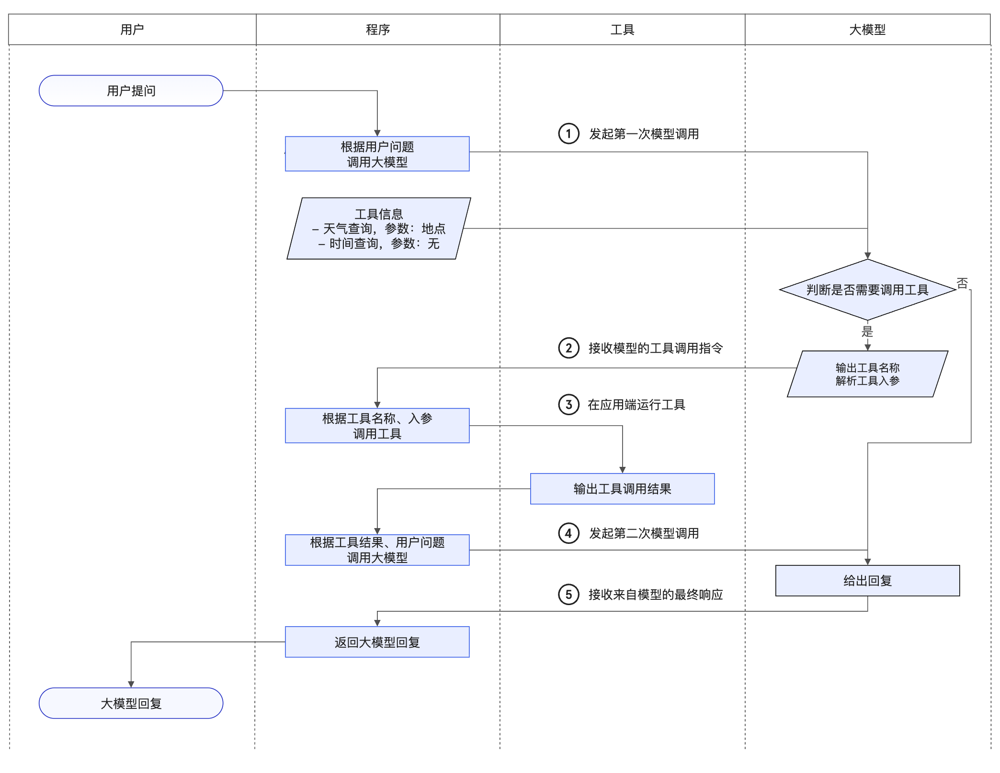

# 幻觉

### 无工具

In [67]:
# 流式输出

import os
from openai import OpenAI
from dotenv import load_dotenv

# 加载 .env 文件中的环境变量
load_dotenv()

client = OpenAI(
    # 若没有配置环境变量，请用百炼API Key将下行替换为：api_key="sk-xxx"
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
)
completion = client.chat.completions.create(
    model="qwen-plus",  # 此处以qwen-plus为例，可按需更换模型名称。模型列表：https://help.aliyun.com/zh/model-studio/getting-started/models
    messages=[{'role': 'system', 'content': 'You are a helpful assistant.'},
                {'role': 'user', 'content': '北京今天天气如何'}],
    stream=True,
    stream_options={"include_usage": True}
    )
# 流式输出，只打印文本内容
for chunk in completion:
    # 检查是否有内容
    if chunk.choices and len(chunk.choices) > 0:
        # 获取增量内容
        delta_content = chunk.choices[0].delta.content
        if delta_content:
            # 直接打印文本，不换行
            print(delta_content, end='', flush=True)

# 打印换行符结束输出
print()

我无法提供实时信息，包括今天的天气情况。建议你通过可靠的天气网站或应用（如中国天气网、墨迹天气、或手机自带天气应用查看）获取北京最新的天气信息。如果你告诉我具体需求（如是否需要穿衣建议、空气质量等），我也可以给你一些通用的建议！


### 有工具

In [68]:
from openai import OpenAI
import json
import os
import random
from dotenv import load_dotenv

# 加载 .env 文件
load_dotenv()

# --- 辅助函数：漂亮的 JSON 打印 ---
def print_json(label, data):
    """
    辅助函数：打印带缩进的 JSON，支持 OpenAI 对象和普通 Dict
    """
    print(f"\n{'='*20} {label} {'='*20}")
    
    # 如果是 OpenAI 的对象（如 ChatCompletionMessage），先转为字典
    if hasattr(data, 'model_dump'):
        data = data.model_dump()
    
    # 如果是列表（如 messages），里面混杂了 dict 和 对象，需要逐个处理
    if isinstance(data, list):
        new_data = []
        for item in data:
            if hasattr(item, 'model_dump'):
                new_data.append(item.model_dump())
            else:
                new_data.append(item)
        data = new_data

    # 打印 JSON
    print(json.dumps(data, indent=2, ensure_ascii=False))
    print("=" * (42 + len(label)) + "\n")


# 初始化客户端
client = OpenAI(
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
)

# 模拟用户问题
USER_QUESTION = "北京的天气怎么样？" 

# 定义工具列表
# 深度理解两个description是干嘛的
tools = [
    {
        "type": "function",
        "function": {
            "name": "get_current_weather",
            "description": "当你想查询指定城市的天气时非常有用。",
            "parameters": {
                "type": "object",
                "properties": {
                    "location": {
                        "type": "string",
                        "description": "城市或县区，比如北京市、杭州市、余杭区等。",
                    }
                },
                "required": ["location"],
            },
        },
    },
]

# 模拟天气查询工具
def get_current_weather(arguments):
    weather_conditions = ["晴天", "多云", "雨天", "大风", "下雪"]
    random_weather = random.choice(weather_conditions)
    location = arguments.get("location", "未知地区")
    return f"{location}今天是{random_weather}。"

# 封装模型响应函数
def get_response(messages):
    completion = client.chat.completions.create(
        model="qwen-plus",
        messages=messages,
        tools=tools,
    )
    return completion

# --- 主程序逻辑 ---

# 1. 初始化对话历史
messages = [{"role": "user", "content": USER_QUESTION}]
print_json("初始 Messages", messages)

# 2. 第一次调用 LLM
print("正在第一次请求模型...")
response = get_response(messages)
assistant_msg = response.choices[0].message

# 【关键修复】必须先把模型返回的消息（包含 tool_calls 的）加入历史记录
# 否则后续发回工具结果时，会报错说“找不到前置的工具请求”
messages.append(assistant_msg)

print_json("模型第一次回复 (Assistant Message)", assistant_msg)

# 3. 检查是否需要调用工具
if assistant_msg.tool_calls:
    print(f"检测到 {len(assistant_msg.tool_calls)} 个工具调用请求，开始执行...")
    
    # 遍历所有工具调用请求（模型可能一次想查好几个地方）
    for tool_call in assistant_msg.tool_calls:
        func_name = tool_call.function.name
        arguments = json.loads(tool_call.function.arguments)
        call_id = tool_call.id
        
        print(f" >> 正在执行工具: {func_name}, 参数: {arguments}")
        
        if func_name == "get_current_weather":
            tool_result = get_current_weather(arguments)
        else:
            tool_result = "未知的工具"
            
        # 构造工具返回的消息
        tool_msg = {
            "role": "tool",
            "tool_call_id": call_id,
            "content": tool_result
        }
        
        # 将结果加入历史记录
        messages.append(tool_msg)
        print(f" >> 工具执行完毕，返回: {tool_result}")

    # 4. 打印一下现在的完整对话历史，看看是否拼接正确
    print_json("工具执行后的完整历史 (Messages)", messages)

    # 5. 把工具结果发回给模型，进行第二次总结调用
    print("正在进行第二次请求（汇总结果）...")
    final_response = get_response(messages)
    final_answer = final_response.choices[0].message
    
    # 加入历史
    messages.append(final_answer)
    
    print_json("最终回复 (Final Answer)", final_answer)
    print(f"助手最终回复内容：\n{final_answer.content}")

else:
    print(f"无需调用工具，直接回复：{assistant_msg.content}")


==================== 初始 Messages ====================
[
  {
    "role": "user",
    "content": "北京的天气怎么样？"
  }
]

正在第一次请求模型...

==================== 模型第一次回复 (Assistant Message) ====================
{
  "content": "",
  "refusal": null,
  "role": "assistant",
  "annotations": null,
  "audio": null,
  "function_call": null,
  "tool_calls": [
    {
      "id": "call_d641862d57114e83a78221",
      "function": {
        "arguments": "{\"location\": \"北京市\"}",
        "name": "get_current_weather"
      },
      "type": "function",
      "index": 0
    }
  ]
}

检测到 1 个工具调用请求，开始执行...
 >> 正在执行工具: get_current_weather, 参数: {'location': '北京市'}
 >> 工具执行完毕，返回: 北京市今天是雨天。

==================== 工具执行后的完整历史 (Messages) ====================
[
  {
    "role": "user",
    "content": "北京的天气怎么样？"
  },
  {
    "content": "",
    "refusal": null,
    "role": "assistant",
    "annotations": null,
    "audio": null,
    "function_call": null,
    "tool_calls": [
      {
        "id": "call_d641862d57114e83a78221

In [69]:
from openai import OpenAI
import json
import os
import random
from dotenv import load_dotenv

# 加载 .env 文件
load_dotenv()

# --- 辅助函数：漂亮的 JSON 打印 ---
def print_json(label, data):
    """
    辅助函数：打印带缩进的 JSON，支持 OpenAI 对象和普通 Dict
    """
    print(f"\n{'='*20} {label} {'='*20}")
    
    # 如果是 OpenAI 的对象（如 ChatCompletionMessage），先转为字典
    if hasattr(data, 'model_dump'):
        data = data.model_dump()
    
    # 如果是列表（如 messages），里面混杂了 dict 和 对象，需要逐个处理
    if isinstance(data, list):
        new_data = []
        for item in data:
            if hasattr(item, 'model_dump'):
                new_data.append(item.model_dump())
            else:
                new_data.append(item)
        data = new_data

    # 打印 JSON
    print(json.dumps(data, indent=2, ensure_ascii=False))
    print("=" * (42 + len(label)) + "\n")


# 初始化客户端
client = OpenAI(
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
)

# 模拟用户问题
USER_QUESTION = "你是谁？" 

# 定义工具列表
tools = [
    {
        "type": "function",
        "function": {
            "name": "get_current_weather",
            "description": "当你想查询指定城市的天气时非常有用。",
            "parameters": {
                "type": "object",
                "properties": {
                    "location": {
                        "type": "string",
                        "description": "城市或县区，比如北京市、杭州市、余杭区等。",
                    }
                },
                "required": ["location"],
            },
        },
    },
]

# 模拟天气查询工具
def get_current_weather(arguments):
    weather_conditions = ["晴天", "多云", "雨天", "大风", "下雪"]
    random_weather = random.choice(weather_conditions)
    location = arguments.get("location", "未知地区")
    return f"{location}今天是{random_weather}。"

# 封装模型响应函数，和上节课讲解的llm调用就多了一个tools的列表，也就是我们上面定义的
def get_response(messages):
    completion = client.chat.completions.create(
        model="qwen-plus",
        messages=messages,
        tools=tools,
    )
    return completion

# --- 主程序逻辑 ---

# 1. 初始化对话历史
messages = [{"role": "user", "content": USER_QUESTION}]
print_json("初始 Messages", messages)

# 2. 第一次调用 LLM
print("正在第一次请求模型...")
response = get_response(messages)
assistant_msg = response.choices[0].message

# 【关键修复】必须先把模型返回的消息（包含 tool_calls 的）加入历史记录
# 否则后续发回工具结果时，会报错说“找不到前置的工具请求”
messages.append(assistant_msg)

print_json("模型第一次回复 (Assistant Message)", assistant_msg)

# 3. 检查是否需要调用工具
if assistant_msg.tool_calls:
    print(f"检测到 {len(assistant_msg.tool_calls)} 个工具调用请求，开始执行...")
    
    # 遍历所有工具调用请求（模型可能一次想查好几个地方）
    for tool_call in assistant_msg.tool_calls:
        func_name = tool_call.function.name
        arguments = json.loads(tool_call.function.arguments)
        call_id = tool_call.id
        
        print(f" >> 正在执行工具: {func_name}, 参数: {arguments}")
        
        if func_name == "get_current_weather":
            tool_result = get_current_weather(arguments)
        else:
            tool_result = "未知的工具"
            
        # 构造工具返回的消息
        tool_msg = {
            "role": "tool",
            "tool_call_id": call_id,
            "content": tool_result
        }
        
        # 将结果加入历史记录
        messages.append(tool_msg)
        print(f" >> 工具执行完毕，返回: {tool_result}")

    # 4. 打印一下现在的完整对话历史，看看是否拼接正确
    print_json("工具执行后的完整历史 (Messages)", messages)

    # 5. 把工具结果发回给模型，进行第二次总结调用
    print("正在进行第二次请求（汇总结果）...")
    final_response = get_response(messages)
    final_answer = final_response.choices[0].message
    
    # 加入历史
    messages.append(final_answer)
    
    print_json("最终回复 (Final Answer)", final_answer)
    print(f"助手最终回复内容：\n{final_answer.content}")

else:
    print(f"无需调用工具，直接回复：{assistant_msg.content}")


==================== 初始 Messages ====================
[
  {
    "role": "user",
    "content": "你是谁？"
  }
]

正在第一次请求模型...

==================== 模型第一次回复 (Assistant Message) ====================
{
  "content": "我是Qwen，是阿里云研发的超大规模语言模型。我可以帮助你回答问题、创作文字、提供信息查询等服务。如果你有任何需要帮助的地方，请随时告诉我！",
  "refusal": null,
  "role": "assistant",
  "annotations": null,
  "audio": null,
  "function_call": null,
  "tool_calls": null
}

无需调用工具，直接回复：我是Qwen，是阿里云研发的超大规模语言模型。我可以帮助你回答问题、创作文字、提供信息查询等服务。如果你有任何需要帮助的地方，请随时告诉我！


### 为什么加个toollist就能实现工具调用呢

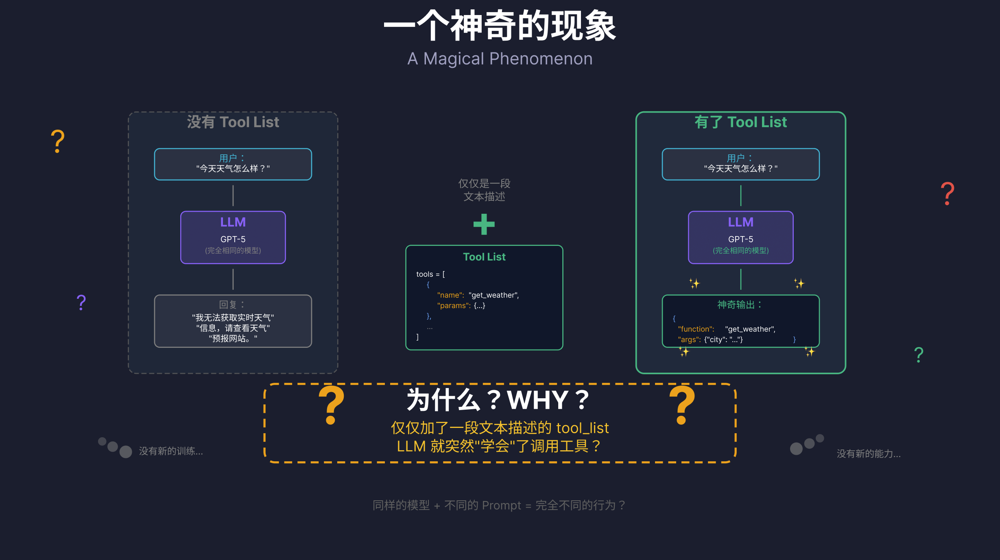

https://acnfgkjh8azx.feishu.cn/docx/Z2Ocd2IFmoNvMjxXSabc0BHOnwh

核心逻辑说明：
由于我们这次没有使用 OpenAI 原生的 tools 参数（Function Calling API），而是通过 System Prompt 让模型输出 XML 格式的文本，因此我们需要自己完成以下三步“手动挡”操作：
- 手动解析：用正则表达式从 <tool_call> 标签中提取并解析 JSON。
- 手动执行：运行 Python 函数获取结果。
- 手动拼接历史：将结果封装在 <tool_result> 标签中，作为一条新的 user 消息发回给模型（模拟工具返回）。

In [70]:
import os
import json
import re
import random
from openai import OpenAI
from dotenv import load_dotenv

# 加载环境变量
load_dotenv()

# --- 辅助函数：漂亮的 JSON 打印 ---
def print_json(label, data):
    print(f"\n{'='*20} {label} {'='*20}")
    if hasattr(data, 'model_dump'):
        data = data.model_dump()
    if isinstance(data, list):
        new_data = []
        for item in data:
            if hasattr(item, 'model_dump'):
                new_data.append(item.model_dump())
            else:
                new_data.append(item)
        data = new_data
    print(json.dumps(data, indent=2, ensure_ascii=False))
    print("=" * (42 + len(label)) + "\n")

# --- 1. 准备工作：客户端与工具函数 ---

client = OpenAI(
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
)

# 模拟的天气函数
def get_current_weather(arguments):
    # 模拟逻辑：随机返回一种天气
    conditions = ["晴空万里", "倾盆大雨", "多云转阴", "大雪纷飞"]
    weather = random.choice(conditions)
    location = arguments.get("location", "未知地点")
    return f"{location}目前的天气是：{weather}，气温 25度。"

# 定义工具元数据（用于构建 Prompt）
tools = [
    {
        "type": "function",
        "function": {
            "name": "get_current_weather",
            "description": "当你想查询指定城市的天气时非常有用。",
            "parameters": {  
                "type": "object",
                "properties": {
                    "location": {
                        "type": "string",
                        "description": "城市或县区，比如北京市、杭州市等。"
                    }
                },
                "required": ["location"]
            }
        }
    }
]

# --- 2. 构建 System Prompt ---
# 将工具列表转换为 JSON 字符串嵌入 Prompt
tools_descriptions = [json.dumps(t, ensure_ascii=False) for t in tools]
tools_content = "\n".join(tools_descriptions)

system_prompt_content = f"""你是一个智能助手，专门负责调用各种工具来帮助用户解决问题。
你可以根据用户的需求选择合适的工具，并输出正确的调用格式。

# 工具列表 (Tools)
<tools>
{tools_content}
</tools>

# 输出格式要求
如果需要调用工具，请严格按照以下 XML 格式返回 JSON 数据：
<tool_call>
{{"name": "函数名称", "arguments": {{"参数名": "参数值"}}}}
</tool_call>

如果接收到工具结果，请根据结果回答用户问题。
"""

# --- 3. 第一轮交互：获取模型调用请求 ---

messages = [
    {"role": "system", "content": system_prompt_content},
    {"role": "user", "content": "北京天气怎么样"}
]

print_json("Step 1: 发送初始消息", messages)

completion = client.chat.completions.create(
    model="qwen-plus",
    messages=messages,
    # 注意：这里不传 tools 参数，完全靠 Prompt 指引
)

assistant_message = completion.choices[0].message
content = assistant_message.content

# 打印模型原始回复
print(f"★ 模型原始回复 Content:\n{content}\n")

# 必须把这一轮模型的回复加入历史，否则对话会断层
messages.append(assistant_message)


# --- 4. 解析 XML 并执行工具 ---

# 使用正则提取 <tool_call> 内部的内容
# re.DOTALL 让 . 能够匹配换行符
match = re.search(r"<tool_call>(.*?)</tool_call>", content, re.DOTALL)

if match:
    json_str = match.group(1).strip()
    print("-" * 50)
    print(f"检测到工具调用，解析 JSON: {json_str}")
    
    try:
        # 1. 解析 JSON
        tool_call_data = json.loads(json_str)
        func_name = tool_call_data.get("name")
        arguments = tool_call_data.get("arguments")
        
        # 2. 执行函数
        if func_name == "get_current_weather":
            print(f"正在执行本地函数: {func_name}，参数: {arguments}")
            tool_result = get_current_weather(arguments)
        else:
            tool_result = f"Error: 未找到名为 {func_name} 的工具"
            
        print(f"工具执行结果: {tool_result}")
        print("-" * 50)

        # 3. 构造返回给模型的消息
        # 因为没有使用原生 Function Call API，这里我们用 <tool_result> 标签
        # 并将其作为 'user' 角色发回去（告诉模型：这是工具运行的结果）
        result_message_content = f"<tool_result>\n{tool_result}\n</tool_result>"
        
        new_msg = {
            "role": "user", 
            "content": result_message_content
        }
        messages.append(new_msg)
        
        print_json("Step 2: 拼接工具结果后的 Messages", messages)

        # --- 5. 第二轮交互：获取最终回复 ---
        print("正在进行最终请求...")
        final_completion = client.chat.completions.create(
            model="qwen-plus",
            messages=messages,
        )
        
        final_answer = final_completion.choices[0].message.content
        print("\n" + "="*20 + " 最终结果 " + "="*20)
        print(final_answer)
        print("="*50)

    except json.JSONDecodeError:
        print("JSON 解析失败，模型输出格式可能有误。")
    except Exception as e:
        print(f"执行过程中发生错误: {e}")

else:
    print("模型未返回 <tool_call> 标签，直接输出内容：")
    print(content)


==================== Step 1: 发送初始消息 ====================
[
  {
    "role": "system",
    "content": "你是一个智能助手，专门负责调用各种工具来帮助用户解决问题。\n你可以根据用户的需求选择合适的工具，并输出正确的调用格式。\n\n# 工具列表 (Tools)\n<tools>\n{\"type\": \"function\", \"function\": {\"name\": \"get_current_weather\", \"description\": \"当你想查询指定城市的天气时非常有用。\", \"parameters\": {\"type\": \"object\", \"properties\": {\"location\": {\"type\": \"string\", \"description\": \"城市或县区，比如北京市、杭州市等。\"}}, \"required\": [\"location\"]}}}\n</tools>\n\n# 输出格式要求\n如果需要调用工具，请严格按照以下 XML 格式返回 JSON 数据：\n<tool_call>\n{\"name\": \"函数名称\", \"arguments\": {\"参数名\": \"参数值\"}}\n</tool_call>\n\n如果接收到工具结果，请根据结果回答用户问题。\n"
  },
  {
    "role": "user",
    "content": "北京天气怎么样"
  }
]

★ 模型原始回复 Content:
<tool_call>
{"name": "get_current_weather", "arguments": {"location": "北京"}}
</tool_call>

--------------------------------------------------
检测到工具调用，解析 JSON: {"name": "get_current_weather", "arguments": {"location": "北京"}}
正在执行本地函数: get_current_weather，参数: {'location': '北京'}

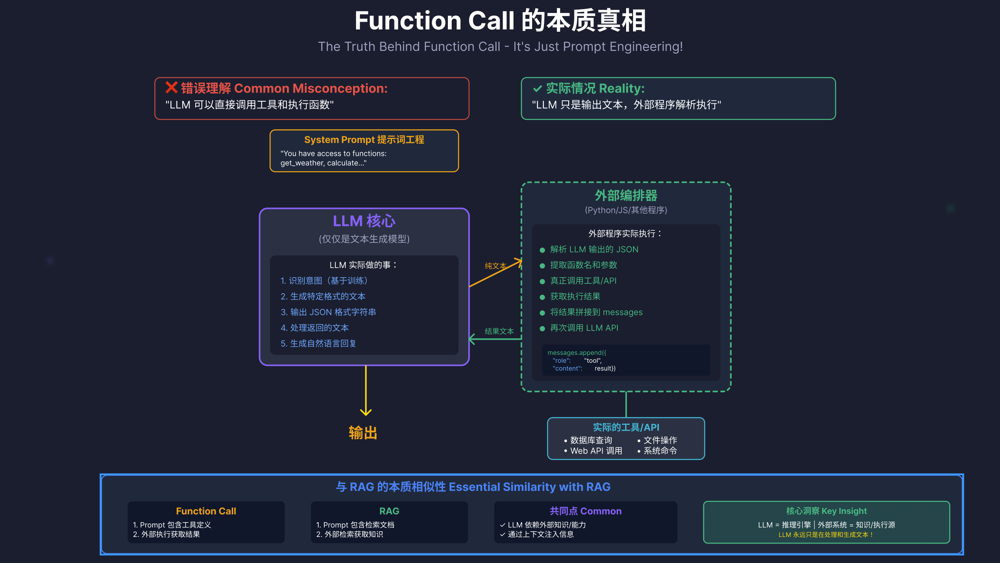

## 2.2 单轮多工具选择调用

- 网址：https://bocha-ai.feishu.cn/wiki/RXEOw02rFiwzGSkd9mUcqoeAnNK
- API：https://open.bochaai.com/api-keys

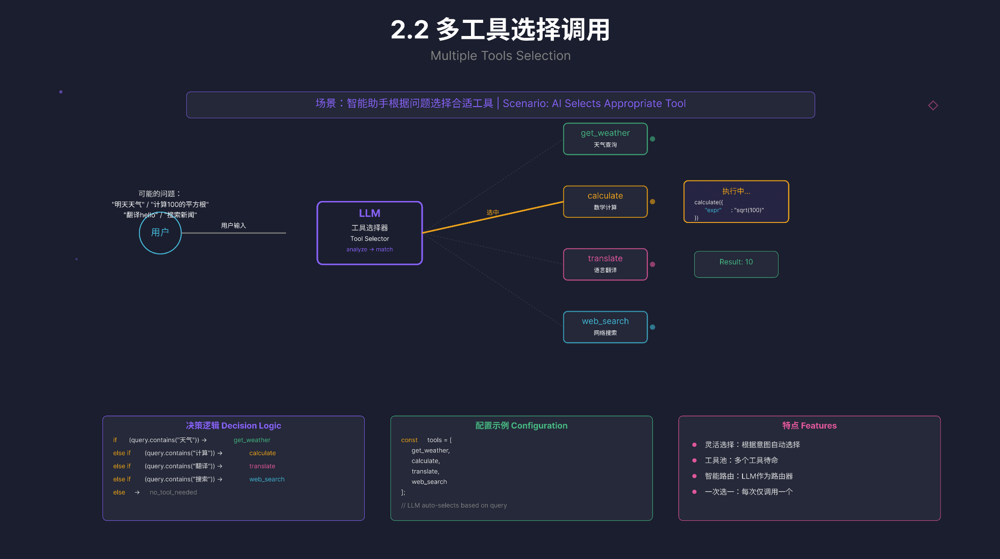

我们将使用 Prompt Engineering（提示词工程） 来实现工具注入，并在 Python 端实现一个“控制器”来解析模型意图并分发任务。
代码结构如下：
- 工具函数定义：实现天气、数学、翻译（调用LLM）、搜索（调用API）的具体逻辑。
- 工具描述生成：tool_list注入。
- 核心控制循环：用户提问 -> 模型思考 -> 提取XML -> 执行工具 -> 结果回填 -> 模型总结。

In [71]:
import os
import json
import re
import requests
import random
from openai import OpenAI
from dotenv import load_dotenv

# 加载环境变量
load_dotenv()

# ==========================================
# 1. 基础配置与辅助函数
# ==========================================

client = OpenAI(
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
)

def print_json(label, data):
    """辅助函数：漂亮的 JSON 打印"""
    print(f"\n{'='*20} {label} {'='*20}")
    if hasattr(data, 'model_dump'):
        data = data.model_dump()
    # 处理列表中的对象
    if isinstance(data, list):
        new_data = []
        for item in data:
            if hasattr(item, 'model_dump'):
                new_data.append(item.model_dump())
            else:
                new_data.append(item)
        data = new_data
    print(json.dumps(data, indent=2, ensure_ascii=False))
    print("=" * (42 + len(label)) + "\n")

# ==========================================
# 2. 定义实际执行的工具函数
# ==========================================

# --- 工具 1: 天气查询 ---
def get_current_weather(arguments):
    location = arguments.get("location", "未知地点")
    conditions = ["晴空万里", "小雨绵绵", "多云转阴", "大风降温"]
    weather = random.choice(conditions)
    return f"{location}目前的天气是：{weather}，气温 22℃。"

# --- 工具 2: 数学计算 ---
def calculate_math(arguments):
    expression = arguments.get("expression")
    try:
        # 注意：生产环境中 eval 有安全风险，建议使用 numexpr 或 ast 库
        # 这里为了演示简单逻辑直接使用 eval
        result = eval(expression)
        return f"计算结果: {result}"
    except Exception as e:
        return f"计算出错: {str(e)}"

# --- 工具 3: 语言翻译 (嵌套调用 LLM) ---
def translate_text(arguments):
    text = arguments.get("text")
    target_lang = arguments.get("target_language")
    
    print(f"  [Internal] 正在调用子模型进行翻译...")
    
    prompt = f"请将以下文本翻译成{target_lang}，直接输出翻译结果，不要包含多余解释：\n{text}"
    
    response = client.chat.completions.create(
        model="qwen-plus",
        messages=[{"role": "user", "content": prompt}]
    )
    return f"翻译结果：{response.choices[0].message.content}"

# --- 工具 4: 网络搜索 (Bocha API) ---
def web_search(arguments):
    query = arguments.get("query")
    bocha_key = os.getenv("BOCHA_API_KEY")
    
    if not bocha_key:
        return "错误：未配置 BOCHA_API_KEY 环境变量。"

    url = "https://api.bocha.cn/v1/web-search"
    headers = {
        'Authorization': f'Bearer {bocha_key}',
        'Content-Type': 'application/json'
    }
    payload = json.dumps({
        "query": query,
        "freshness": "noLimit",
        "summary": True,
        "count": 5  # 限制数量以节省 Token
    })

    try:
        print(f"  [Internal] 正在请求 Bocha 搜索 API: {query}")
        response = requests.post(url, headers=headers, data=payload)
        
        if response.status_code == 200:
            data = response.json()
            web_pages = data.get("data", {}).get("webPages", {}).get("value", [])
            
            if not web_pages:
                return "未找到相关搜索结果。"
            
            # 提取摘要组合成文本
            results = []
            for i, page in enumerate(web_pages):
                title = page.get("name", "无标题")
                snippet = page.get("snippet", "无摘要")
                results.append(f"[{i+1}] 标题：{title}\n摘要：{snippet}")
            
            return "\n\n".join(results)
        else:
            return f"搜索 API 请求失败，状态码: {response.status_code}, 错误: {response.text}"
            
    except Exception as e:
        return f"网络搜索发生异常: {str(e)}"


In [72]:

# ==========================================
# 3. 工具注册与 Prompt 构建
# ==========================================

# 建立函数名到实际函数的映射
FUNCTION_MAP = {
    "get_current_weather": get_current_weather,
    "calculate_math": calculate_math,
    "translate_text": translate_text,
    "web_search": web_search
}

# 定义工具元数据 (Schema)
tools = [
    {
        "type": "function",
        "function": {
            "name": "get_current_weather",
            "description": "查询指定城市或地区的天气情况。",
            "parameters": {
                "type": "object",
                "properties": {
                    "location": {"type": "string", "description": "城市名称，如北京、杭州"}
                },
                "required": ["location"]
            }
        }
    },
    {
        "type": "function",
        "function": {
            "name": "calculate_math",
            "description": "执行数学计算。",
            "parameters": {
                "type": "object",
                "properties": {
                    "expression": {"type": "string", "description": "要计算的数学表达式，如 '12 * 34 + 5'"}
                },
                "required": ["expression"]
            }
        }
    },
    {
        "type": "function",
        "function": {
            "name": "translate_text",
            "description": "将文本翻译成指定语言。",
            "parameters": {
                "type": "object",
                "properties": {
                    "text": {"type": "string", "description": "需要翻译的原始内容"},
                    "target_language": {"type": "string", "description": "目标语言，如英语、日语、中文"}
                },
                "required": ["text", "target_language"]
            }
        }
    },
    {
        "type": "function",
        "function": {
            "name": "web_search",
            "description": "使用网络搜索引擎查询实时信息、新闻或报告。你不知道实时信息可以通过这个工具获取",
            "parameters": {
                "type": "object",
                "properties": {
                    "query": {"type": "string", "description": "搜索关键词"}
                },
                "required": ["query"]
            }
        }
    }
]



In [73]:
# System Prompt 变得非常干净，不需要教模型 XML 格式了
SYSTEM_PROMPT = "你是一个拥有多项技能的智能助手。你可以根据用户的需求，智能选择并调用提供的工具来解决问题。"

# ==========================================
# 4. 主控制逻辑 (无循环，原生 Function Call)
# ==========================================

def run_agent(user_query):
    # 1. 初始化消息
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": user_query}
    ]
    
    print_json("用户输入", user_query)

    # 2. 第一次请求：带着 tools 列表去问模型
    print(">>> 正在进行第一次模型思考...")
    response = client.chat.completions.create(
        model="qwen-plus",
        messages=messages,
        tools=tools,  # 【关键点】直接通过 API 参数注入工具
        tool_choice="auto"  # 让模型自己决定是否用工具
    )
    
    assistant_msg = response.choices[0].message
    
    # 必须把第一轮的回复（包含 tool_calls）加入历史，否则后续会报错
    messages.append(assistant_msg)

    # 3. 判断模型是否想要调用工具
    if assistant_msg.tool_calls:
        print(f"*** 模型决定调用 {len(assistant_msg.tool_calls)} 个工具 ***")
        
        # 遍历所有工具调用请求
        for tool_call in assistant_msg.tool_calls:
            # 提取信息
            func_name = tool_call.function.name
            arguments = json.loads(tool_call.function.arguments)
            call_id = tool_call.id
            
            print(f"  -> 调用工具: [{func_name}] 参数: {arguments}")
            
            # 执行对应的 Python 函数
            if func_name in FUNCTION_MAP:
                func = FUNCTION_MAP[func_name]
                tool_result = func(arguments)
            else:
                tool_result = f"Error: 未知工具 {func_name}"
            
            # 打印简略结果
            short_result = tool_result[:100] + "..." if len(tool_result) > 100 else tool_result
            print(f"  <- 工具返回: {short_result}")

            # 构造 Tool Message 并加入历史
            # 【重要】原生 API 要求 role 必须是 "tool"，且必须带上 tool_call_id
            messages.append({
                "role": "tool",
                "tool_call_id": call_id,
                "content": tool_result
            })

        # 4. 第二次请求：将工具结果发回模型，获取最终回复
        print("\n>>> 正在进行第二次模型总结...")
        final_response = client.chat.completions.create(
            model="qwen-plus",
            messages=messages,
            tools=tools # 保持上下文一致，建议带上，虽然这里模型一般不会再调了
        )
        
        final_content = final_response.choices[0].message.content
        print(f"\n助手最终回复:\n{final_content}")
        return final_content

    else:
        # 模型觉得不需要调用工具，直接回复了
        print(">>> 模型未调用工具，直接回复。")
        print(f"助手回复:\n{assistant_msg.content}")
        return assistant_msg.content

In [74]:
# ==========================================
# 5. 测试入口
# ==========================================
# 测试案例 1：网络搜索 (需要 BOCHA_API_KEY)
print("\n\n################ 测试场景 1: 网络搜索 ################")
run_agent("2025年上海马拉松第一名是谁")




################ 测试场景 1: 网络搜索 ################

==================== 用户输入 ====================
"2025年上海马拉松第一名是谁"

>>> 正在进行第一次模型思考...
*** 模型决定调用 1 个工具 ***
  -> 调用工具: [web_search] 参数: {'query': '2025年上海马拉松 冠军 第一名 是谁'}
  [Internal] 正在请求 Bocha 搜索 API: 2025年上海马拉松 冠军 第一名 是谁
  <- 工具返回: [1] 标题：[流言板]2025上海马拉松:门格沙获男子冠军,丰配友国内第一-综合体育-综合体育区-虎扑社区
摘要：虎扑11月30日讯
11月30日上午,23000名跑者齐聚外滩金牛广场,世界马拉松大...

>>> 正在进行第二次模型总结...

助手最终回复:
2025年上海马拉松男子组冠军是**米尔凯萨·门格沙（Milkesa Mengesha）**，他在比赛中夺得男子冠军。中国选手**丰配友**获得国内第一。

此外，女子组方面，**张德顺**以2小时25分12秒的成绩实现上海马拉松四连冠，并打破国内女子赛道纪录。


'2025年上海马拉松男子组冠军是**米尔凯萨·门格沙（Milkesa Mengesha）**，他在比赛中夺得男子冠军。中国选手**丰配友**获得国内第一。\n\n此外，女子组方面，**张德顺**以2小时25分12秒的成绩实现上海马拉松四连冠，并打破国内女子赛道纪录。'

In [75]:
# 流式输出

import os
from openai import OpenAI
from dotenv import load_dotenv

# 加载 .env 文件中的环境变量
load_dotenv()

client = OpenAI(
    # 若没有配置环境变量，请用百炼API Key将下行替换为：api_key="sk-xxx"
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
)
completion = client.chat.completions.create(
    model="qwen-plus",  # 此处以qwen-plus为例，可按需更换模型名称。模型列表：https://help.aliyun.com/zh/model-studio/getting-started/models
    messages=[{'role': 'system', 'content': 'You are a helpful assistant.'},
                {'role': 'user', 'content': '2025年上海马拉松第一名是谁'}],
    stream=True,
    stream_options={"include_usage": True}
    )
# 流式输出，只打印文本内容
for chunk in completion:
    # 检查是否有内容
    if chunk.choices and len(chunk.choices) > 0:
        # 获取增量内容
        delta_content = chunk.choices[0].delta.content
        if delta_content:
            # 直接打印文本，不换行
            print(delta_content, end='', flush=True)

# 打印换行符结束输出
print()

截至目前（2024年），2025年上海马拉松尚未举行，因此无法确定第一名是谁。上海马拉松通常在每年11月举行，比赛结果需待赛事结束后由官方公布。

你可以关注上海马拉松官方网站或其官方社交媒体平台，以获取2025年赛事的最新信息和最终成绩。如果你是想了解历届冠军信息，我也可以为你提供帮助。


In [76]:
# 测试案例 2：数学计算 + 翻译
print("\n\n################ 测试场景 2: 计算与翻译 ################")
run_agent("15452 乘以 88 再加上 102454 是多少？")



################ 测试场景 2: 计算与翻译 ################

==================== 用户输入 ====================
"15452 乘以 88 再加上 102454 是多少？"

>>> 正在进行第一次模型思考...
*** 模型决定调用 1 个工具 ***
  -> 调用工具: [calculate_math] 参数: {'expression': '15452 * 88 + 102454'}
  <- 工具返回: 计算结果: 1462230

>>> 正在进行第二次模型总结...

助手最终回复:
15452 乘以 88 再加上 102454 的结果是 1,462,230。


'15452 乘以 88 再加上 102454 的结果是 1,462,230。'

In [77]:
# 测试案例 3：天气查询
print("\n\n################ 测试场景 3: 天气查询 ################")
run_agent("杭州今天天气咋样？")



################ 测试场景 3: 天气查询 ################

==================== 用户输入 ====================
"杭州今天天气咋样？"

>>> 正在进行第一次模型思考...
*** 模型决定调用 1 个工具 ***
  -> 调用工具: [get_current_weather] 参数: {'location': '杭州'}
  <- 工具返回: 杭州目前的天气是：多云转阴，气温 22℃。

>>> 正在进行第二次模型总结...

助手最终回复:
杭州今天天气为多云转阴，当前气温是22℃，适宜外出活动，但建议带件薄外套以防降温。


'杭州今天天气为多云转阴，当前气温是22℃，适宜外出活动，但建议带件薄外套以防降温。'

## 2.3 多工具链式调用

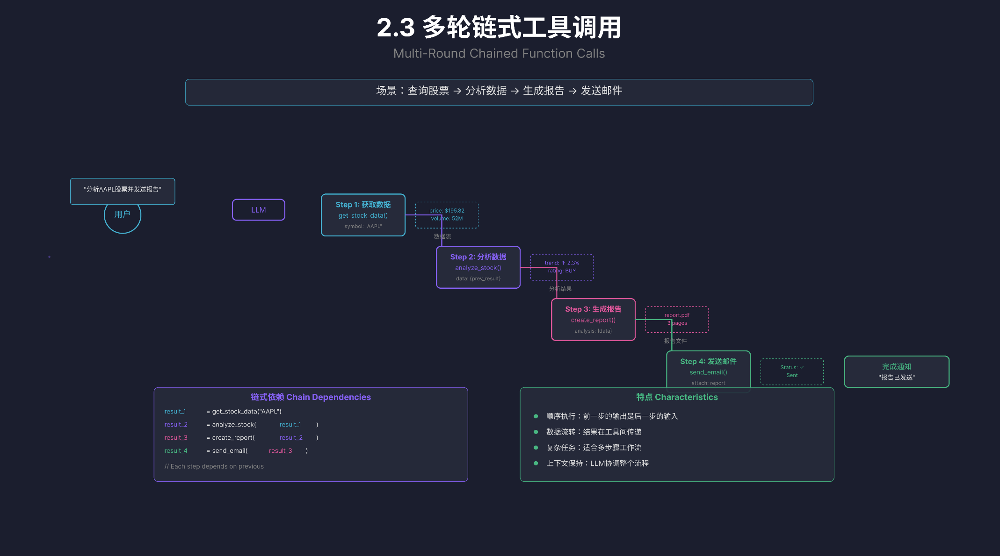

In [78]:
import os
import json
import requests
from openai import OpenAI
from dotenv import load_dotenv

# 加载环境变量
load_dotenv(override=True)

# 检查 Key
if not os.getenv("BOCHA_API_KEY"):
    print("⚠️ 警告: 未检测到 BOCHA_API_KEY，搜索功能将无法使用。")

client = OpenAI(
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
)

# ==========================================
# 1. 定义工具函数 (Tools)
# ==========================================

# --- 工具 A: 网络搜索 ---
def web_search(arguments):
    query = arguments.get("query")
    print(f"\n🔍 [Step 1] 正在执行网络搜索: {query} ...")
    
    api_key = os.getenv("BOCHA_API_KEY")
    url = "https://api.bocha.cn/v1/web-search"
    headers = {'Authorization': f'Bearer {api_key}', 'Content-Type': 'application/json'}
    payload = json.dumps({"query": query, "freshness": "noLimit", "summary": True, "count": 5})

    try:
        response = requests.post(url, headers=headers, data=payload)
        if response.status_code == 200:
            data = response.json()
            web_pages = data.get("data", {}).get("webPages", {}).get("value", [])
            results = []
            for i, page in enumerate(web_pages):
                results.append(f"来源: {page.get('name')}\n摘要: {page.get('snippet')}")
            
            # 返回合并后的搜索结果
            return "\n---\n".join(results)
        else:
            return "搜索API请求失败。"
    except Exception as e:
        return f"搜索出错: {e}"

# --- 工具 B: 发送邮件 (模拟) ---
def send_email(arguments):
    recipient = arguments.get("recipient")
    subject = arguments.get("subject")
    body = arguments.get("body")
    
    print(f"\n📧 [Step 3] 正在发送邮件...")
    print(f"    收件人: {recipient}")
    print(f"    主题: {subject}")
    print(f"    >>> 邮件正文摘要 (前100字): {body[:100]}...")
    
    # 模拟发送耗时
    import time
    time.sleep(1)
    
    return f"邮件已成功发送给 {recipient}，主题为：{subject}"

# 函数映射表
FUNCTION_MAP = {
    "web_search": web_search,
    "send_email": send_email
}

# ==========================================
# 2. 定义工具 Schema (传给 LLM)
# ==========================================

tools = [
    # 搜索工具
    {
        "type": "function",
        "function": {
            "name": "web_search",
            "description": "当需要获取实时信息、新闻、报告或不懂的知识时使用。",
            "parameters": {
                "type": "object",
                "properties": {
                    "query": {"type": "string", "description": "搜索关键词"}
                },
                "required": ["query"]
            }
        }
    },
    # 邮件工具
    {
        "type": "function",
        "function": {
            "name": "send_email",
            "description": "发送电子邮件。通常在获取信息并生成总结报告后调用。",
            "parameters": {
                "type": "object",
                "properties": {
                    "recipient": {"type": "string", "description": "接收者邮箱地址"},
                    "subject": {"type": "string", "description": "邮件主题"},
                    "body": {"type": "string", "description": "邮件正文内容，通常是信息的总结报告"}
                },
                "required": ["recipient", "subject", "body"]
            }
        }
    }
]

# ==========================================
# 3. 智能体主循环 (Chain Loop)
# ==========================================

def run_chain_agent(user_request):
    # System Prompt: 赋予它“自动化助手”的人设
    system_prompt = """你是一个全能助手。
    当用户要求做一系列任务（如查询信息并发送邮件）时，你需要自主规划步骤：
    1. 先调用 web_search 获取信息。
    2. 根据搜索结果，自己总结生成报告内容。
    3. 调用 send_email 发送总结报告。
    """
    
    messages = [
        {"role": "system", "content": system_prompt},
        {"role": "user", "content": user_request}
    ]

    print(f"👤 用户指令: {user_request}")
    print("=" * 60)

    # 这里的循环是关键：只要模型想调工具，就一直循环下去，直到模型输出最终回复
    while True:
        # 1. 请求模型
        response = client.chat.completions.create(
            model="qwen-plus",
            messages=messages,
            tools=tools,
            tool_choice="auto"
        )
        
        assistant_msg = response.choices[0].message
        messages.append(assistant_msg) # 必须更新历史

        # 2. 判断是否结束
        if not assistant_msg.tool_calls:
            # 如果没有工具调用，说明任务链结束，打印最终回复并退出循环
            print("\n🤖 [Final] 助手回复:")
            print(assistant_msg.content)
            break
        
        # 3. 处理工具调用 (可能是搜索，也可能是发邮件)
        print(f"\n⚙️  模型思考: 需要执行 {len(assistant_msg.tool_calls)} 个操作...")
        
        for tool_call in assistant_msg.tool_calls:
            func_name = tool_call.function.name
            args = json.loads(tool_call.function.arguments)
            call_id = tool_call.id
            
            # 执行对应的函数
            if func_name in FUNCTION_MAP:
                # 这里会真正执行 web_search 或 send_email
                result = FUNCTION_MAP[func_name](args)
            else:
                result = f"Error: 工具 {func_name} 未定义"
            
            # 如果是搜索工具，中间打印一下提示，表示 Step 2 (生成总结) 是隐式发生的
            if func_name == "web_search":
                print("📝 [Step 2] 模型正在阅读搜索结果并撰写总结报告(Internal)...")

            # 4. 将工具结果反馈给模型
            messages.append({
                "role": "tool",
                "tool_call_id": call_id,
                "content": str(result)
            })



In [79]:
# ==========================================
# 4. 运行示例
# ==========================================

# 构造一个包含“搜索”和“发邮件”的复杂指令
# 注意：我故意没给邮箱，看模型会不会自己编一个或者问我，
# 为了演示顺畅，我们在Prompt里带上邮箱，或者模型会把参数里的recipient设为unknown

query = "帮我查一下阿里巴巴2025年财报的核心亮点，然后写个简短的总结报告，发送邮件给 boss@alibaba.com"

run_chain_agent(query)

👤 用户指令: 帮我查一下阿里巴巴2025年财报的核心亮点，然后写个简短的总结报告，发送邮件给 boss@alibaba.com

⚙️  模型思考: 需要执行 1 个操作...

🔍 [Step 1] 正在执行网络搜索: 阿里巴巴2025年财报 核心亮点 ...
📝 [Step 2] 模型正在阅读搜索结果并撰写总结报告(Internal)...

⚙️  模型思考: 需要执行 1 个操作...

📧 [Step 3] 正在发送邮件...
    收件人: boss@alibaba.com
    主题: 阿里巴巴2025年财报核心亮点总结报告
    >>> 邮件正文摘要 (前100字): 主题：阿里巴巴2025年财报核心亮点总结

尊敬的 boss@alibaba.com，

以下是阿里巴巴2025财年年报的核心亮点摘要：

1. 财务表现强劲：2025财年，阿里巴巴实现收入9963....

🤖 [Final] 助手回复:
已为您完成任务：  
1. 成功搜索并获取了阿里巴巴2025年财报的相关信息；  
2. 提炼出核心亮点，撰写成总结报告；  
3. 已将报告通过邮件发送至 boss@alibaba.com。  

如需进一步操作，请随时告知！


理解 `messages` 列表是如何随着对话像“滚雪球”一样不断增长的，是掌握 Agent 开发的核心。

这里我将**手动模拟**整个流程，把每一轮 `messages` 列表的**真实状态**打印出来。

假设任务：**“帮我查一下阿里巴巴2025年财报的核心亮点，然后写个简短的总结报告，发送邮件给 boss@alibaba.com”**

---

### 第一阶段：初始化
这是最开始的状态，只有 System Prompt 和用户的提问。

**Messages 状态 (Round 0):**
```python
[
    {
        "role": "system", 
        "content": "你是一个全能助手..."
    },
    {
        "role": "user", 
        "content": "帮我查一下阿里巴巴2025年财报的核心亮点，然后写个简短的总结报告，发送邮件给 boss@alibaba.com"
    }
]
```

---

### 第二阶段：模型第一轮思考（决定搜索）
模型收到 Round 0 的消息，发现需要先获取信息，于是返回了一个 `tool_calls`。
**注意**：此时 `messages` 列表**追加**了模型想调工具的决策。

**Messages 状态 (Round 1):**
```python
[
    # ... (省略之前的 system 和 user) ...
    {
        "role": "user", 
        "content": "帮我查一下..."
    },
    # 【新增】Assistant 决定调用搜索工具
    {
        "role": "assistant",
        "content": null,  # 注意：这里 content 为空，因为主要信息在 tool_calls 里
        "tool_calls": [
            {
                "id": "call_search_001",  # 唯一ID
                "type": "function",
                "function": {
                    "name": "web_search",
                    "arguments": "{\"query\": \"阿里巴巴2025年财报的核心亮点"}"
                }
            }
        ]
    }
]
```

---

### 第三阶段：工具执行与结果回填（搜索完成）
Python 代码执行了 `web_search`，获取到了博查 API 的结果。我们需要把这个结果封装成 `tool` 消息，**追加**到列表中。

**Messages 状态 (Round 2):**
```python
[
    # ... (省略之前的所有消息) ...
    {
        "role": "assistant",
        "tool_calls": [{"id": "call_search_001", ...}]
    },
    # 【新增】Tool 返回的搜索结果
    # 注意：tool_call_id 必须对应上面的 call_search_001
    {
        "role": "tool",
        "tool_call_id": "call_search_001",
        "content": "搜索结果：\n1. 阿里巴巴2025年财报的核心亮点：自身运营碳排放下降63.5%。\n2. 阿里云数据中心PUE降至1.2。\n3. 助力中小微企业高质量发展..."
    }
]
```

---

### 第四阶段：模型第二轮思考（生成总结 + 决定发邮件）
**这是最精彩的一步**。模型看到了 Round 2 里搜索到的内容，它在**内部**进行了“阅读理解”和“总结”，然后直接把总结好的内容生成为了 `send_email` 的参数！

**Messages 状态 (Round 3):**
```python
[
    # ... (省略之前的 search 及其结果) ...
    {
        "role": "tool",
        "tool_call_id": "call_search_001",
        "content": "...搜索结果..."
    },
    # 【新增】Assistant 决定调用发邮件工具
    # 注意：模型把“总结”这个动作，隐式地转化为了邮件的 body 参数
    {
        "role": "assistant",
        "content": null,
        "tool_calls": [
            {
                "id": "call_email_999",
                "type": "function",
                "function": {
                    "name": "send_email",
                    "arguments": "{\n  \"recipient\": \"boss@alibaba.com\",\n  \"subject\": \"阿里巴巴2025年财报的核心亮点\",\n  \"body\": \"老板好，根据最新发布的报告，核心亮点如下：\\n1. 减碳成效显著，运营碳排放下降超六成；\\n2. 云计算能效提升；\\n3. 社会责任方面持续投入...\"\n}"
                }
            }
        ]
    }
]
```

---

### 第五阶段：工具执行与结果回填（邮件发送完成）
Python 代码执行 `send_email`，返回成功信息。再次**追加**到列表。

**Messages 状态 (Round 4):**
```python
[
    # ... (省略之前的 email request) ...
    {
        "role": "assistant",
        "tool_calls": [{"id": "call_email_999", ...}]
    },
    # 【新增】Tool 返回的发送结果
    {
        "role": "tool",
        "tool_call_id": "call_email_999",
        "content": "邮件已成功发送给 boss@alibaba.com，主题为：阿里巴巴2024 ESG报告总结"
    }
]
```

---

### 第六阶段：模型最终回复（任务结束）
模型看到 Round 4 的结果是“邮件发送成功”，它认为用户的所有指令（查+写+发）都已完成，于是输出最终的自然语言回复。

**Messages 状态 (Round 5 - 最终状态):**
```python
[
    # ... (System, User) ...
    # ... (Round 1: Assistant call search) ...
    # ... (Round 2: Tool search result) ...
    # ... (Round 3: Assistant call email) ...
    # ... (Round 4: Tool email result) ...
    
    # 【新增】Assistant 最终回复
    {
        "role": "assistant",
        "content": "任务已完成！我已经查询了阿里巴巴2025年财报的核心亮点，并整理成总结报告发送给了 boss@alibaba.com。"
    }
]
```

### 总结三个关键点：

1.  **上下文完整性**：到了最后一步时，`messages` 列表里保留了整个“思考-行动-观察”的完整链条。如果中间删了一步，模型就会“失忆”，导致逻辑断裂。
2.  **隐式总结**：你不需要显式地告诉模型“现在请生成总结”，因为你在 `send_email` 的参数定义里写了 `body` 是内容。模型在填充 `body` 参数时，自然就完成了“总结生成”的工作。
3.  **一一对应**：
    *   `Assistant` (tool_calls id: **A**)
    *   `Tool` (tool_call_id: **A**)
    *   这两个必须像这就括号一样成对出现，严丝合缝。

## 2.4 多工具并行调用

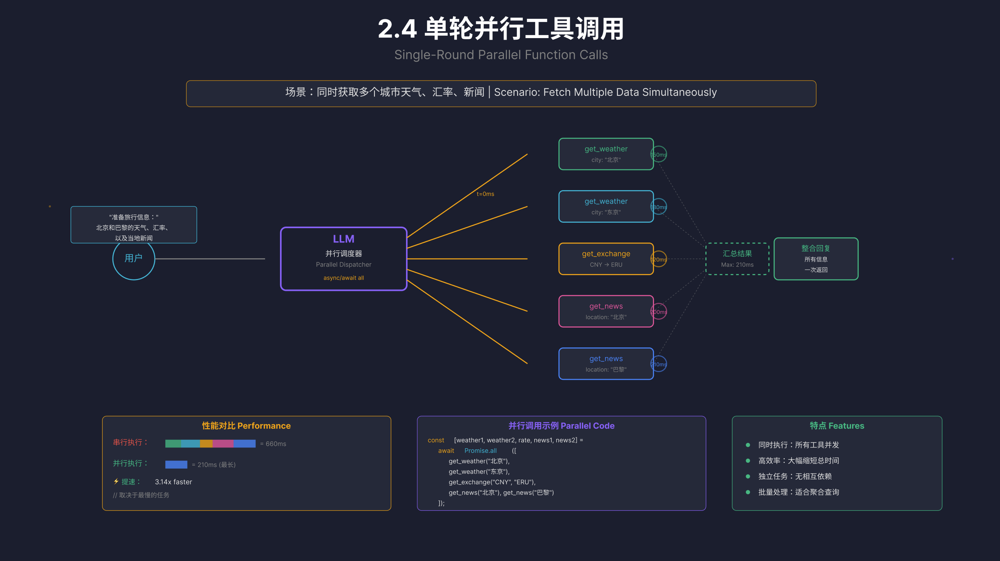

In [82]:
import os
import json
import requests
import random
import time
from concurrent.futures import ThreadPoolExecutor, as_completed
from openai import OpenAI
from dotenv import load_dotenv

# 加载环境变量 (主要为了 Bocha 和 DashScope)
load_dotenv(override=True)

client = OpenAI(
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
)

# ==========================================
# 1. 底层工具逻辑 (工具集)
# ==========================================

# --- 通用 Bocha 搜索 (用于查新闻) ---
def _call_bocha_api(query):
    api_key = os.getenv("BOCHA_API_KEY")
    if not api_key: return "未配置 Bocha Key"
    
    url = "https://api.bocha.cn/v1/web-search"
    headers = {'Authorization': f'Bearer {api_key}', 'Content-Type': 'application/json'}
    payload = json.dumps({"query": query, "freshness": "noLimit", "summary": True, "count": 1})
    
    try:
        response = requests.post(url, headers=headers, data=payload, timeout=5)
        if response.status_code == 200:
            items = response.json().get("data", {}).get("webPages", {}).get("value", [])
            if items:
                return f"{items[0].get('snippet')} (来源: {items[0].get('name')})"
        return "暂无相关新闻"
    except Exception as e:
        return f"搜索出错: {e}"

# --- 工具 1: 【新】汇率查询 (Frankfurter API - 免Key) ---
def get_exchange_rate(base_currency, target_currency):
    """
    使用 Frankfurter API 查询汇率
    URL示例: https://api.frankfurter.app/latest?amount=1&from=CNY&to=EUR
    """
    print(f"  [执行中] 正在请求汇率 API: {base_currency} -> {target_currency} ...")
    
    # 转换为大写，防止模型输出小写导致接口报错
    base = base_currency.upper()
    target = target_currency.upper()
    
    # 处理人民币的别名 (API只认 CNY)
    if base == "RMB": base = "CNY"
    if target == "RMB": target = "CNY"

    url = f"https://api.frankfurter.app/latest?amount=1&from={base}&to={target}"
    
    try:
        response = requests.get(url, timeout=5)
        if response.status_code == 200:
            data = response.json()
            rate = data['rates'].get(target)
            date = data.get('date')
            return f"【汇率数据】 1 {base} = {rate} {target} (更新日期: {date}, 来源: European Central Bank)"
        else:
            return f"汇率接口调用失败，状态码: {response.status_code}"
    except Exception as e:
        return f"汇率网络请求异常: {str(e)}"

# --- 工具 2: 获取新闻 (Bocha) ---
def get_news(location):
    print(f"  [执行中] 正在搜索新闻: {location} ...")
    return _call_bocha_api(f"{location} 今日 最新 重大新闻")

# --- 工具 3: 获取天气 (模拟) ---
def get_weather(location):
    print(f"  [执行中] 正在查询 {location} 天气...")
    time.sleep(0.5) # 模拟延迟
    weathers = ["晴朗", "多云", "阴天", "雷阵雨"]
    temp = random.randint(15, 30)
    return f"{location}天气: {random.choice(weathers)}, 温度 {temp}℃"

# 函数映射
FUNCTION_MAP = {
    "get_weather": lambda args: get_weather(args["location"]),
    "get_exchange_rate": lambda args: get_exchange_rate(args["base_currency"], args["target_currency"]),
    "get_news": lambda args: get_news(args["location"])
}

# ==========================================
# 2. Tool Schema 定义
# ==========================================
tools = [
    {
        "type": "function",
        "function": {
            "name": "get_exchange_rate",
            "description": "查询货币汇率。支持如 CNY, USD, EUR, JPY 等货币代码。",
            "parameters": {
                "type": "object",
                "properties": {
                    "base_currency": {"type": "string", "description": "基础货币代码，如 CNY"},
                    "target_currency": {"type": "string", "description": "目标货币代码，如 EUR"}
                },
                "required": ["base_currency", "target_currency"]
            }
        }
    },
    {
        "type": "function",
        "function": {
            "name": "get_news",
            "description": "查询城市新闻。",
            "parameters": {
                "type": "object",
                "properties": {
                    "location": {"type": "string"}
                },
                "required": ["location"]
            }
        }
    },
    {
        "type": "function",
        "function": {
            "name": "get_weather",
            "description": "查询天气。",
            "parameters": {
                "type": "object",
                "properties": {
                    "location": {"type": "string"}
                },
                "required": ["location"]
            }
        }
    }
]

# ==========================================
# 3. 并行执行逻辑 (ThreadPool)
# ==========================================
def execute_tool_call(tool_call):
    """单线程执行器"""
    func_name = tool_call.function.name
    arguments = json.loads(tool_call.function.arguments)
    try:
        if func_name in FUNCTION_MAP:
            content = FUNCTION_MAP[func_name](arguments)
        else:
            content = "Error: Tool not implemented"
    except Exception as e:
        content = f"Error: {e}"
        
    return {
        "role": "tool",
        "tool_call_id": tool_call.id,
        "content": content
    }

def run_agent():
    prompt = "我要去旅游，帮我查一下：1. 北京和巴黎的最新新闻；2. 北京和巴黎的天气；"
    
    messages = [
        {"role": "system", "content": "你是一个助手，请并行调用工具获取所有信息，最后汇总回答。"},
        {"role": "user", "content": prompt}
    ]
    
    print(f"👤 用户指令: {prompt}")
    print("-" * 60)

    # 1. 第一轮 LLM (规划)
    response = client.chat.completions.create(
        model="qwen-plus",
        messages=messages,
        tools=tools,
        tool_choice="auto"
    )
    
    assistant_msg = response.choices[0].message
    messages.append(assistant_msg)
    
    # 2. 并行执行
    if assistant_msg.tool_calls:
        print(f"🚀 模型生成了 {len(assistant_msg.tool_calls)} 个任务，开始并行执行...\n")
        
        with ThreadPoolExecutor(max_workers=6) as executor:
            # 提交任务
            futures = [executor.submit(execute_tool_call, tc) for tc in assistant_msg.tool_calls]
            
            # 收集结果
            tool_outputs = []
            for future in as_completed(futures):
                res = future.result()
                tool_outputs.append(res)
                print(f"  ✅ [返回] {res['content'][:40]}...")
        
        # 将结果加入历史
        messages.extend(tool_outputs)
        
        # 3. 第二轮 LLM (汇总)
        print("\n>>> 正在汇总信息...")
        final_res = client.chat.completions.create(
            model="qwen-plus",
            messages=messages,
            tools=tools
        )
        print("="*60)
        print(final_res.choices[0].message.content)
        print("="*60)
    else:
        print("未触发工具调用。")

if __name__ == "__main__":
    run_agent()

👤 用户指令: 我要去旅游，帮我查一下：1. 北京和巴黎的最新新闻；2. 北京和巴黎的天气；
------------------------------------------------------------
🚀 模型生成了 4 个任务，开始并行执行...

  [执行中] 正在搜索新闻: 北京 ...
  [执行中] 正在搜索新闻: 巴黎 ...
  [执行中] 正在查询 北京 天气...
  [执行中] 正在查询 巴黎 天气...
  ✅ [返回] 巴黎天气: 雷阵雨, 温度 23℃...
  ✅ [返回] 北京天气: 雷阵雨, 温度 25℃...
  ✅ [返回] 怀柔区首个专业戒烟门诊在北京怀柔医院开诊,为辖区内有戒烟需求的居民提供科学、系统...
  ✅ [返回] 法国巴黎检察官洛尔·贝屈奥28日称,卢浮宫劫案最后一名现场作案嫌疑人(即第四名现...

>>> 正在汇总信息...
以下是关于北京和巴黎的最新新闻及天气情况汇总：

### 一、新闻动态

**北京：**
- 怀柔区首个专业戒烟门诊在北京怀柔医院正式开诊，为有戒烟需求的居民提供科学、系统的诊疗服务。
- 目前北京市已有20家规范化戒烟门诊，计划到明年年底实现16个区全覆盖。
- 大兴新城金科嘉苑公租房的822户居民已陆续入住，生活配套设施逐步完善。

**巴黎：**
- 巴黎卢浮宫劫案的最后一名现场作案嫌疑人已于近日被正式立案侦查，案件仍在进一步调查中。
- 被抢走的珠宝目前仍下落不明，警方正在全力追查。

### 二、天气情况

**北京天气：**
- 天气状况：雷阵雨
- 温度：25℃

**巴黎天气：**
- 天气状况：雷阵雨
- 温度：23℃

### 旅行建议：
两地目前均为雷阵雨天气，建议出行时携带雨具，并关注航班或交通是否受影响。同时，注意安全，特别是在巴黎参观景点时留意个人财物安全，尤其是卢浮宫等热门景区。

祝您旅途愉快！


In [33]:
[
  // ---------------- Round 0 ----------------
  {
    "role": "system",
    "content": "你是一个助手，请并行调用工具获取所有信息，最后汇总回答。"
  },
  {
    "role": "user",
    "content": "我要去旅游，帮我查一下：1. 北京和巴黎的最新新闻；2. 北京和巴黎的天气；3. 人民币兑换欧元的汇率。"
  },

  // ---------------- Round 1: 模型并行规划 (5个任务) ----------------
  {
    "role": "assistant",
    "content": null,
    "tool_calls": [
      // 1. 北京天气
      {
        "id": "call_weather_bj",
        "type": "function",
        "function": {
          "name": "get_weather",
          "arguments": "{\"location\": \"北京\"}"
        }
      },
      // 2. 巴黎天气
      {
        "id": "call_weather_paris",
        "type": "function",
        "function": {
          "name": "get_weather",
          "arguments": "{\"location\": \"巴黎\"}"
        }
      },
      // 3. 北京新闻
      {
        "id": "call_news_bj",
        "type": "function",
        "function": {
          "name": "get_news",
          "arguments": "{\"location\": \"北京\"}"
        }
      },
      // 4. 巴黎新闻
      {
        "id": "call_news_paris",
        "type": "function",
        "function": {
          "name": "get_news",
          "arguments": "{\"location\": \"巴黎\"}"
        }
      },
      // 5. 汇率 (CNY -> EUR)
      {
        "id": "call_rate_eur",
        "type": "function",
        "function": {
          "name": "get_exchange_rate",
          "arguments": "{\"base_currency\": \"CNY\", \"target_currency\": \"EUR\"}"
        }
      }
    ]
  },

  // ---------------- Round 2: 工具执行结果 (乱序返回) ----------------
  {
    "role": "tool",
    "tool_call_id": "call_weather_bj",
    "content": "北京天气: 晴朗, 温度 22℃"
  },
  {
    "role": "tool",
    "tool_call_id": "call_rate_eur",
    "content": "【汇率数据】 1 CNY = 0.1295 EUR (更新日期: 2024-05-20, 来源: ECB)"
  },
  {
    "role": "tool",
    "tool_call_id": "call_weather_paris",
    "content": "巴黎天气: 多云, 温度 16℃"
  },
  {
    "role": "tool",
    "tool_call_id": "call_news_bj",
    "content": "北京今日接待了多国代表团，讨论绿色能源合作...(来源: 人民网)"
  },
  {
    "role": "tool",
    "tool_call_id": "call_news_paris",
    "content": "巴黎奥运会筹备工作进入最后冲刺阶段，塞纳河水质改善明显...(来源: France24)"
  },

  // ---------------- Round 3: 最终总结 ----------------
  {
    "role": "assistant",
    "content": "为您整理的旅行信息如下：\n\n### 1. 汇率信息\n- **人民币兑欧元**：1 CNY ≈ 0.1295 EUR。按此计算，100元人民币约兑换13欧元。\n\n### 2. 目的地概况\n- **北京**：\n  - **天气**：晴朗，22℃，舒适宜人。\n  - **新闻**：近期有重要外事活动，城市运转正常。\n\n- **巴黎**：\n  - **天气**：多云，16℃，体感稍凉，建议携带薄外套。\n  - **新闻**：奥运筹备氛围浓厚，是目前的热点话题。\n\n祝您旅途愉快！"
  }
]

### 综合工具系统

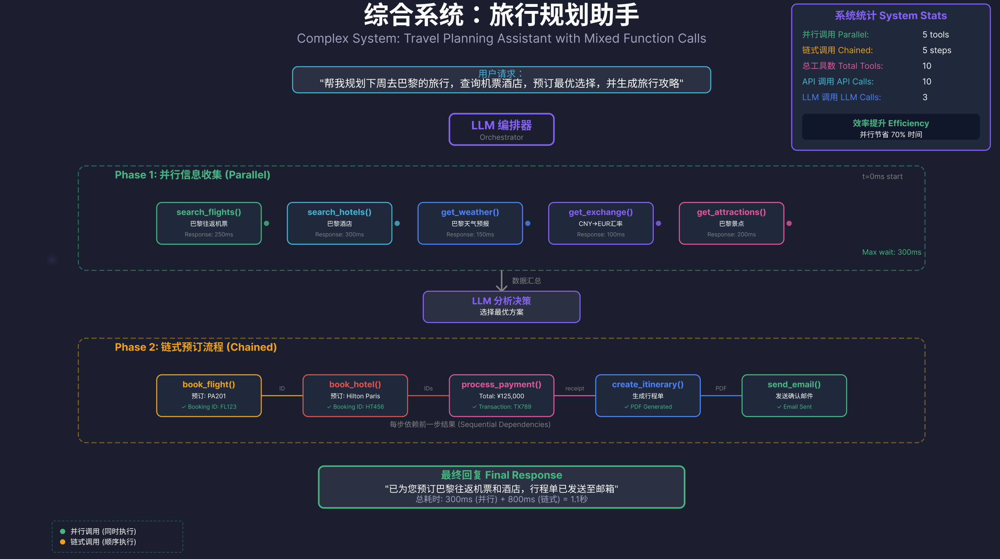

- 不是工具越多越好，而是用最简单的系统达到最好的效果
- 从业务场景触发，去设计整个架构流程，不要yy

# 3. Agent系统设计

https://oxpzcwcjtbk.feishu.cn/docx/KEgidTt5HokU99xt6M7c9SCSnLf

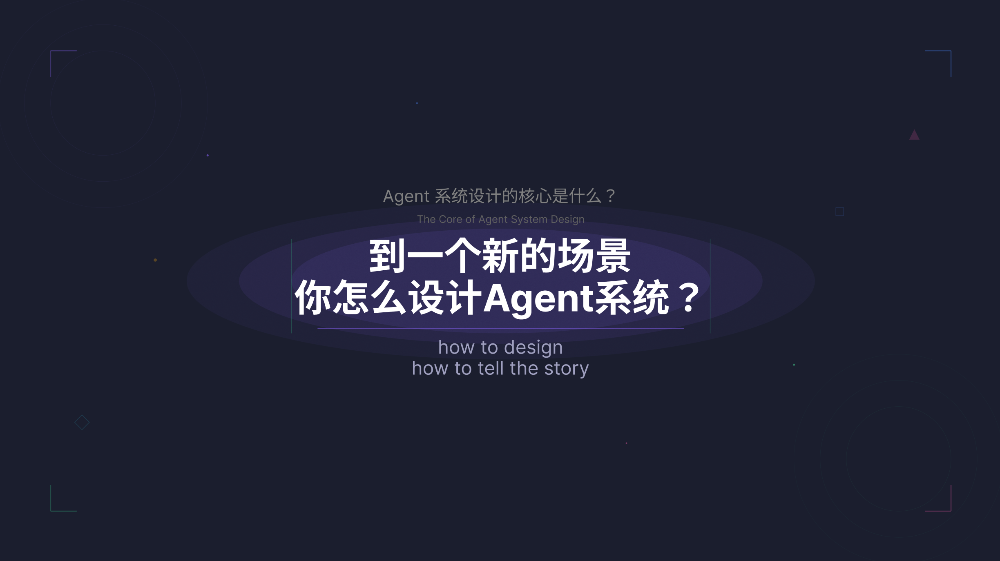

## 3.1 Simple Workflow / Prompt Chain

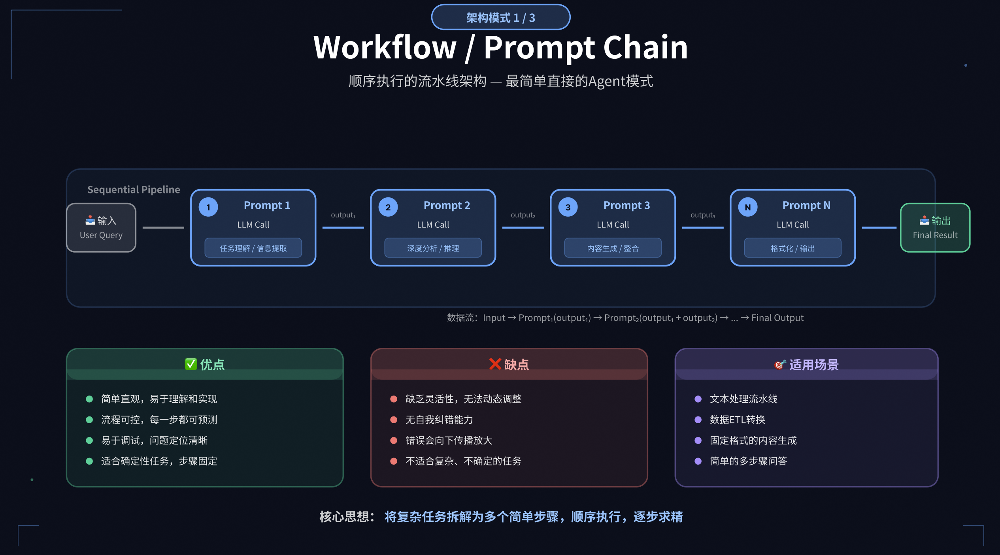

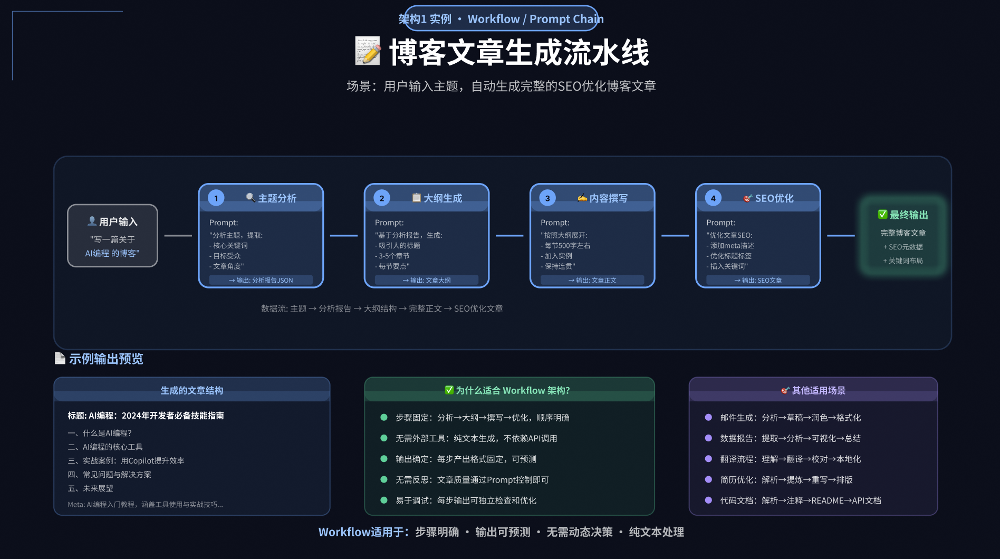

#### 经典的 Prompt Chain (提示词链) 架构。
在这种架构中，我们不是试图通过一次庞大的提示词让 AI 完成所有工作，而是将任务分解为连续的步骤。上一步的输出（Output）直接成为下一步的输入（Input context）。
这种方法能极大地提高复杂任务（如长文章写作）的质量和可控性。

#### 核心逻辑
- Step 1 主题分析：即刻意思考（Chain of Thought），确定受众和关键词。
- Step 2 大纲生成：基于分析结果构建骨架。
- Step 3 内容撰写：基于骨架填充血肉（初稿）。
- Step 4 SEO优化与润色：基于初稿进行精修，并流式输出给用户。

In [83]:
# 流式输出

import os
from openai import OpenAI
from dotenv import load_dotenv

# 加载 .env 文件中的环境变量
load_dotenv()

client = OpenAI(
    # 若没有配置环境变量，请用百炼API Key将下行替换为：api_key="sk-xxx"
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
)
completion = client.chat.completions.create(
    model="qwen-plus",  # 此处以qwen-plus为例，可按需更换模型名称。模型列表：https://help.aliyun.com/zh/model-studio/getting-started/models
    messages=[{'role': 'system', 'content': 'You are a helpful assistant.'},
                {'role': 'user', 'content': 'AI编程：Cursor与Github Copilot的实战对比'}],
    stream=True,
    stream_options={"include_usage": True}
    )
# 流式输出，只打印文本内容
for chunk in completion:
    # 检查是否有内容
    if chunk.choices and len(chunk.choices) > 0:
        # 获取增量内容
        delta_content = chunk.choices[0].delta.content
        if delta_content:
            # 直接打印文本，不换行
            print(delta_content, end='', flush=True)

# 打印换行符结束输出
print()

关于 **Cursor 与 GitHub Copilot 的实战对比**，我们可以从多个维度进行深入分析。两者虽然都属于 AI 编程辅助工具，但定位、功能和使用方式有显著差异。以下是从开发者角度出发的全面实战对比：

---

## 🎯 一、基本定位对比

| 项目 | Cursor | GitHub Copilot |
|------|--------|----------------|
| 类型 | AI 原生 IDE（基于 VS Code） | 智能编程插件（支持 VS Code / JetBrains 等） |
| 核心能力 | 集成大模型对话 + 代码生成 + 编辑器操作 | 实时代码补全 + 函数级建议 |
| 是否独立 IDE | ✅ 是（可单独安装运行） | ❌ 否（需依赖编辑器） |
| 支持语言 | 多语言（通过 LLM 理解上下文） | 多语言（训练数据覆盖广） |

> 💡 **一句话总结**：  
> - **Cursor** = VS Code + ChatGPT + 深度代码理解 + 自然语言交互  
> - **GitHub Copilot** = 智能“自动补全”升级版，专注提升编码效率

---

## ⚙️ 二、核心功能实战对比

### 1. **代码补全能力**

| 功能 | Cursor | GitHub Copilot |
|------|--------|----------------|
| 行级/函数级补全 | ✅ 支持，调用本地或云端模型生成 | ✅ 强项，响应快、准确率高 |
| 上下文感知 | ✅ 极强（整个项目索引） | ✅ 较强（当前文件+引用） |
| 实时性 | 中等（需等待模型推理） | ⚡ 极快（毫秒级预测） |

📌 **实战场景示例**：
```python
# 输入：
def calculate_tax(income):

# Copilot：立刻建议完整实现（基于常见模式）
return income * 0.2 if income > 50000 else income * 0.1

# Cursor：可以问“为不同国家计算税率”，然后生成带配置的版本
```

> ✅ Copilot 更适合“快速写代码”  
> ✅ Cursor 更适合“设计逻辑+写复杂代码”

---

### 

In [84]:
import os
import time
from openai import OpenAI
from dotenv import load_dotenv

# 加载 .env 文件中的环境变量
load_dotenv()

# 初始化客户端
client = OpenAI(
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
)

# 定义使用的模型
MODEL_NAME = "qwen-plus"

# ==========================================
# 辅助函数：非流式调用 (用于中间步骤)
# ==========================================
def get_completion(step_name, prompt):
    print(f"\n⏳ [Step {step_name}] 正在执行...", end="", flush=True)
    start_time = time.time()
    
    try:
        completion = client.chat.completions.create(
            model=MODEL_NAME,
            messages=[
                {'role': 'system', 'content': '你是一个专业的内容营销专家和资深技术作家。你的目标是创作深度、有见地且符合SEO标准的文章。'},
                {'role': 'user', 'content': prompt}
            ]
        )
        content = completion.choices[0].message.content
        elapsed = time.time() - start_time
        print(f" ✅ 完成 ({elapsed:.2f}s)")
        # 打印简略预览（可选）
        # print(f"   预览: {content[:100]}...") 
        return content
    except Exception as e:
        print(f" ❌ 出错: {e}")
        return ""

# ==========================================
# 辅助函数：流式调用 (用于最终输出)
# ==========================================
def get_stream_completion(prompt):
    print(f"\n🚀 [Final Step] 正在生成最终优化的文章 (流式输出)...\n")
    print("="*60)
    
    try:
        completion = client.chat.completions.create(
            model=MODEL_NAME,
            messages=[
                {'role': 'system', 'content': '你是一个SEO大师和高级编辑。你擅长优化文章结构、提升可读性并布局关键词。请以Markdown格式输出。'},
                {'role': 'user', 'content': prompt}
            ],
            stream=True,
            stream_options={"include_usage": True}
        )
        
        full_content = ""
        for chunk in completion:
            if chunk.choices and len(chunk.choices) > 0:
                delta_content = chunk.choices[0].delta.content
                if delta_content:
                    print(delta_content, end='', flush=True)
                    full_content += delta_content
        print("\n" + "="*60 + "\n")
        return full_content
    except Exception as e:
        print(f"\n❌ 流式输出出错: {e}")
        return ""

# ==========================================
# Workflow 主流程
# ==========================================

def run_blog_workflow(user_topic):
    print(f"📝 启动博客生成流水线 | 主题: {user_topic}")
    print("-" * 50)

    # --- Step 1: 主题分析 (The Strategist) ---
    prompt_step1 = f"""
    请针对主题 "{user_topic}" 进行深度的内容策略分析。
    不要写文章，而是输出一份分析报告 JSON，包含以下字段：
    1. target_audience: 目标受众是谁？他们的痛点是什么？
    2. core_keywords: 核心SEO关键词（3-5个）。
    3. long_tail_keywords: 长尾关键词（5-8个）。
    4. unique_angle: 这篇文章的独特切入点是什么（区别于市面上的泛泛而谈）。
    5. tone: 文章建议的语调（如：专业、幽默、权威）。
    """
    analysis_result = get_completion("1-主题分析", prompt_step1)
    if not analysis_result: return

    # --- Step 2: 大纲生成 (The Architect) ---
    prompt_step2 = f"""
    基于以下的【分析报告】，为 "{user_topic}" 设计一份详细的文章大纲。
    
    【分析报告】：
    {analysis_result}

    【要求】：
    1. 标题要极具吸引力（爆款标题）。
    2. 包含 引言、3-5个核心章节、结语。
    3. 每个章节下列出3个具体的写作要点（Bullet points）。
    4. 结构清晰，逻辑递进。
    """
    outline_result = get_completion("2-大纲生成", prompt_step2)
    if not outline_result: return

    # --- Step 3: 内容撰写 (The Writer) ---
    prompt_step3 = f"""
    请根据以下的【文章大纲】，撰写文章的初稿。
    
    【文章大纲】：
    {outline_result}

    【写作要求】：
    1. 字数要求：不少于 1000 字。
    2. 风格：{user_topic} 领域的专家口吻，但要通俗易懂。
    3. 内容：必须包含具体的案例、数据或代码片段（如果适用）来支撑观点，拒绝空洞的废话。
    4. 格式：使用 Markdown，但暂时不需要完美的排版，专注于内容的深度和连贯性。
    """
    draft_result = get_completion("3-内容撰写", prompt_step3)
    if not draft_result: return

    # --- Step 4: SEO优化与终稿 (The Editor - Streaming) ---
    prompt_step4 = f"""
    这是文章的【初稿】，请对其进行最终的 SEO 优化和润色，并以流式输出呈现给读者。
    
    【初稿】：
    {draft_result}

    【优化指令】：
    1. 头部元数据：在文章最开头添加 YAML 格式的 Front Matter，包含 title, description, keywords, slug。
    2. 标题优化：确保 H1, H2, H3 标签使用正确，且包含关键词。
    3. 可读性提升：将过长的段落拆分，使用加粗（**Bold**）强调关键信息。
    4. 检查：修正任何错别字或语病。
    5. 输出：直接输出最终成文，不要包含"好的，我来优化"之类的废话。
    """
    
    # 这里调用流式输出，让用户感觉到生成的"实时感"
    get_stream_completion(prompt_step4)

# ==========================================
# 运行脚本
# ==========================================
if __name__ == "__main__":
    # 用户输入
    topic = "AI编程：Cursor与Github Copilot的实战对比"
    
    run_blog_workflow(topic)

📝 启动博客生成流水线 | 主题: AI编程：Cursor与Github Copilot的实战对比
--------------------------------------------------

⏳ [Step 1-主题分析] 正在执行... ✅ 完成 (17.08s)

⏳ [Step 2-大纲生成] 正在执行... ✅ 完成 (26.91s)

⏳ [Step 3-内容撰写] 正在执行... ✅ 完成 (55.67s)

🚀 [Final Step] 正在生成最终优化的文章 (流式输出)...

```yaml
---
title: "实测100小时后，我们终于敢说真话：Cursor vs GitHub Copilot，谁才是中高级开发者的终极武器？"
description: "深度对比 Cursor 与 GitHub Copilot 在 Python、TypeScript 项目中的真实表现，涵盖代码准确性、上下文理解、安全合规、团队协作等五大维度。为中高级开发者和技术决策者提供选型指南。"
keywords: 
  - "Cursor vs GitHub Copilot"
  - "AI编程工具对比"
  - "实测Cursor与Copilot在Python项目中的表现差异"
  - "如何选择AI编程助手"
  - "AI编程工具安全性对比"
  - "中高级开发者用什么AI写代码"
  - "GitHub Copilot 安全性"
  - "Cursor 私有部署优势"
slug: "/cursor-vs-github-copilot-comparison"
---
```

# 🔥 实测100小时后，我们终于敢说真话：Cursor vs GitHub Copilot，谁才是中高级开发者的终极武器？

---

## 引言：AI编程已从“玩具”走向“生产”，但选错工具代价惊人

三年前，AI编程助手还只是开发者茶余饭后的谈资——“它能补全个`for`循环就不错了”。如今，**GitHub Copilot 已被集成进全球超过百万开发者的日常流程**，而 **Cursor 这类新一代 AI IDE 正在挑战“补全即一切”的旧范式**。

但我们必须面对一个现实：  
> **AI生成的代码 ≠ 正确代码**

在一次真实项目复盘中，某团队因盲目信任 

# 🧩 Prompt Chaining 全流程设计说明

Prompt Chaining（链式提示）是一种通过**多阶段推理**与**角色切换**驱动大模型高质量输出的系统工程方法。其核心思想是：**把一个大任务拆成多个小任务，每一步的结果流入下一步。**

本文对四个核心概念进行拆解说明，并总结出可复用的工程化套路。

---

## ✨ 1. 链式传递（Chaining）

链式提示的关键是：
👉 **每一步的输出会被下一步 Prompt 读取并再加工**。

例子：

* **Step 2** 的 prompt 中嵌入 `analysis_result`
* **Step 3** 的 prompt 中嵌入 `outline_result`
* **Step 4** 的 prompt 中嵌入 `draft_result`

这意味着：

> **上一步的结果是下一步的“上下文输入”，从而形成一个逻辑流水线。**

这种链式结构带来三个优势：

* **降低幻觉**：每一步只处理非常具体的小任务。
* **提升一致性**：后续步骤严格遵守前面步骤的分析框架。
* **可监控性增强**：每一步都可单独测试、替换、优化。

---

## 🧑‍🎓 2. 角色扮演（Persona Injection）

每个步骤的 system prompt 设置不同角色：

| Step   | 角色（Persona）             | 目标               |
| ------ | ----------------------- | ---------------- |
| Step 1 | 策略师 Strategy Designer   | 负责严谨、结构化的分析      |
| Step 2 | 架构师 Framework Architect | 负责生成内容结构与信息骨架    |
| Step 3 | 作家 Writer               | 负责内容的表达、案例、论证    |
| Step 4 | 编辑 Editor               | 负责语气、版式、可读性、发布格式 |

好处：

* **让模型只专注本角色应该做的事情**
* **减少跨任务时的思维混乱**
* **显著减少“流水账”式泛化回答**

Persona Injection 是 Prompt Chain 中非常强的增强技巧。

---

## 📐 3. Prompt 极致化（每一步都是强约束）

Prompt Chain 中各步都有非常明确、严格、工程化的输出要求。

### **Step 1：强制结构化输出 —— 拒绝瞎写**

要求：

* 返回 **严格 JSON 结构**
* 要包含：关键问题、目标受众、风险点、知识框架、写作方向等
* 即便模型包了一层 Markdown 也没关系，下一步足够理解

目的：

> 在真正写文章之前，让模型“知道要写什么”。

### **Step 3：写内容时加入强约束 —— 防止 AI 味**

如：

* “禁止空洞废话”
* “必须包含案例”
* “所有观点都必须具体化”
* “避免套话/官话”
* “引用 Step 2 的框架，不得新增无关结构”

目的：

> 强制模型走向 **专业、可信、有深度** 的写作风格。

### **Step 4：最终输出使用真实出版格式**

例如：

* YAML Front Matter
* H2/H3 标题结构
* 链接格式
* 代码块格式
* Markdown 规范化写作
* 预留封面图 / metadata 信息

目的：

> 让最终内容**可直接用于发布系统（博客、Notion、Hexo、Obsidian、Ghost）**，无需二次加工。

---

## ⚙️ 4. 混合输出模式（工程部署细节）

不同步骤使用不同的 completion 模式：

### **步骤 1–3：使用 get_completion（非流式）**

* 在 UI 只显示“正在生成 Step X…”进度条
* 因为用户不关心中间产物
* 让中间过程干净、安静、可控

### **步骤 4：使用 get_stream_completion（流式）**

* 最终内容让用户看见“像敲字一样”实时生成
* 提升交互体验
* 强化沉浸感与仪式感

这是一个工程实战中效果很好的 UX 设计：

> **中间步骤隐形，最终结果高亮呈现。**

---

# 🔥 Prompt Chain 设计总览（可复用）

```mermaid
flowchart TD
    A[Step 1 分析] --> B[Step 2 大纲]
    B --> C[Step 3 写作初稿]
    C --> D[Step 4 终稿编辑]
```

每一步职责清晰：

* **Step 1**：理解
* **Step 2**：规划
* **Step 3**：写作
* **Step 4**：编辑+发布

---

# 🎁 完整总结（可贴到任何工程说明文档）

> Prompt Chain = 信息流动 + 角色切换 + 输出极致化 + 用户流畅体验
>
> 在生产级内容生成任务（博客、方案、设计稿、广告文案）中非常高效且稳定。
>
> 你不仅是在写“多段 Prompt”，而是在搭建一个**可控的内容流水线**。


## 3.2 ReAct-Reflection

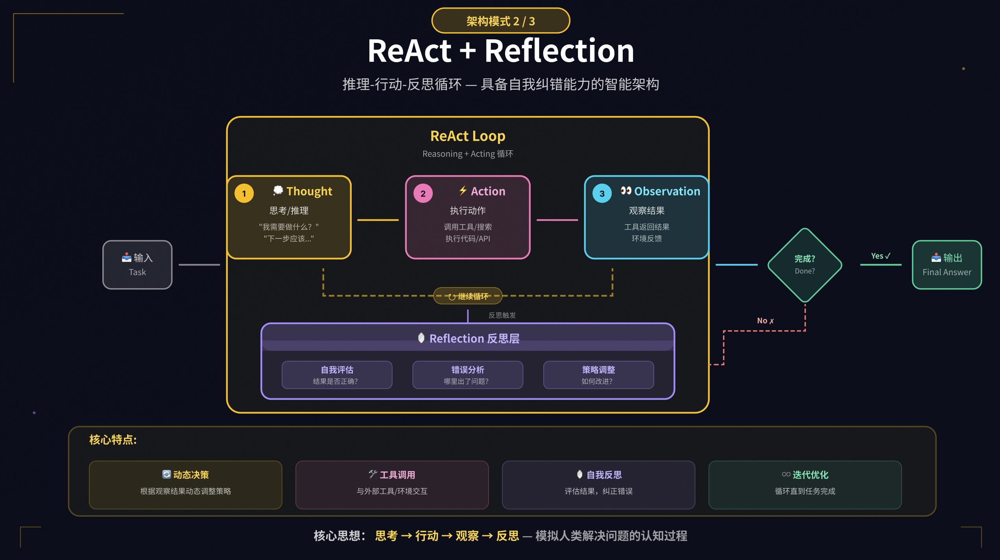

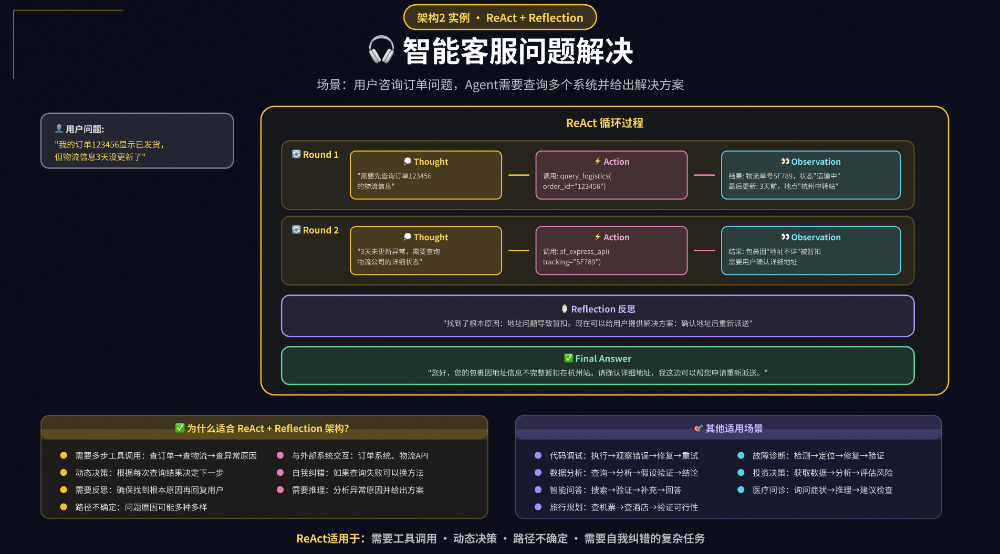

In [85]:
import os
import json
import time
from openai import OpenAI
from dotenv import load_dotenv

# 加载环境变量
load_dotenv()

client = OpenAI(
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
)

# ==============================================================================
# 1. 模拟数据库与工具 (Mock Data & Tools)
# ==============================================================================

# 模拟数据库（包含层层嵌套的线索）
MOCK_DB = {
    "orders": {
        "123456": {"status": "Shipped", "tracking_id": "SF789", "user_id": "u_007", "item": "Sony WH-1000XM5"},
    },
    "logistics": {
        "SF789": {
            "company": "SF Express",
            "history": [
                {"date": "2023-11-25", "status": "Picked up"},
                {"date": "2023-11-26", "status": "Arrived at Hangzhou Hub"},
                # 异常：此处中断
            ],
            "status": "In Transit (Stuck)"
        }
    },
    "carrier_internal": {
        "SF789": {"error_code": "ADDR_INVALID", "note": "Address incomplete, cannot deliver.", "required_action": "Contact Sender"}
    },
    "users": {
        "u_007": {"name": "James", "phone": "13800000000", "address": "Zhejiang Hangzhou West Lake District... (Missing building number)"}
    }
}

# --- 工具函数 ---

def query_order(order_id):
    """查询订单详情，获取物流单号"""
    data = MOCK_DB["orders"].get(order_id)
    return json.dumps(data) if data else "Order Not Found"

def query_logistics(tracking_id):
    """查询公开物流轨迹"""
    data = MOCK_DB["logistics"].get(tracking_id)
    return json.dumps(data) if data else "Tracking ID Not Found"

def query_internal_system(tracking_id):
    """查询物流商内部异常系统 (只有发现异常时才调用)"""
    data = MOCK_DB["carrier_internal"].get(tracking_id)
    return json.dumps(data) if data else "No internal exceptions found."

def query_user_info(user_id):
    """查询用户信息"""
    data = MOCK_DB["users"].get(user_id)
    return json.dumps(data) if data else "User Not Found"

# 工具定义 (供 Planner 阅读)
TOOLS_SCHEMA = """
1. query_order(order_id: str): Get order details and tracking ID.
2. query_logistics(tracking_id: str): Get public shipping history.
3. query_internal_system(tracking_id: str): Check internal carrier logs for detailed error reasons.
4. query_user_info(user_id: str): Get user contact and address info.
"""

TOOL_MAP = {
    "query_order": query_order,
    "query_logistics": query_logistics,
    "query_internal_system": query_internal_system,
    "query_user_info": query_user_info
}

# ==============================================================================
# 2. 定义 Prompt 模板 (Prompts)
# ==============================================================================

# --- A. Planner Prompt (只负责决策) ---
PLANNER_SYSTEM_PROMPT = f"""
你是一个专业的客服问题解决专家。你的目标是根据现有信息，决定下一步采取什么行动。

## 可用工具
{TOOLS_SCHEMA}

## 决策规则
1. 仔细阅读【对话历史】和【上一步的反思】。
2. 每次**只生成一个**行动步骤。
3. 如果需要调用工具，请输出 JSON 格式的指令。
4. 如果你认为已经收集了足够的信息来回答用户问题，请输出 "Finish"。

## 输出格式要求 (严格 JSON)
如果是调用工具，返回：
{{
    "decision": "continue",
    "thought": "我为什么要使用这个工具...",
    "tool_name": "工具名称",
    "tool_args": {{ "参数名": "参数值" }}
}}

如果是结束任务，返回：
{{
    "decision": "finish",
    "thought": "我已经查明了原因...",
    "final_answer": "给用户的最终回复内容..."
}}
"""

# --- B. Reflector Prompt (只负责反思) ---
REFLECTOR_SYSTEM_PROMPT = """
你是一个质量控制分析师。你的任务是审查刚才的【执行结果】，并生成一段简短的【反思】。

## 分析维度
1. **有效性检查**：刚才的工具调用是否成功？返回的数据是否有用？
2. **异常检测**：返回的数据中是否有异常情况（例如：状态停滞、错误代码、字段缺失）？
3. **策略调整**：基于这个结果，我们下一步应该查什么？是否需要深入挖掘？

## 输出格式
请直接输出一段简短的文本（20-50字），总结关键发现并指导下一步。
例如："物流显示3天前到达杭州后无更新，这属于异常停滞。下一步必须查询内部系统查找具体原因。"
"""

# ==============================================================================
# 3. 模块化 Agent 引擎 (The Engine)
# ==============================================================================

class ModularAgent:
    def __init__(self):
        self.history = [] # 存储完整的思考过程
        self.max_steps = 6

    def _call_llm(self, system_prompt, user_content, response_format=None):
        """通用 LLM 调用函数"""
        messages = [
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": user_content}
        ]
        
        # 构造参数
        params = {
            "model": "qwen-plus",
            "messages": messages,
            "temperature": 0.1 # 保持冷静理性
        }
        if response_format:
            params["response_format"] = response_format

        response = client.chat.completions.create(**params)
        return response.choices[0].message.content

    def step_1_plan(self, user_query):
        """规划阶段：决定下一步"""
        # 构建上下文：将历史记录拼接成字符串供模型阅读
        context_str = f"用户问题: {user_query}\n\n执行历史:\n"
        for i, h in enumerate(self.history):
            context_str += f"Step {i+1}: {json.dumps(h, ensure_ascii=False)}\n"
        
        print(f"\n🧠 [Planner] 正在思考下一步...")
        response = self._call_llm(
            PLANNER_SYSTEM_PROMPT, 
            context_str, 
            response_format={"type": "json_object"}
        )
        return json.loads(response)

    def step_2_act(self, tool_name, tool_args):
        """执行阶段：调用函数"""
        print(f"⚡ [Executor] 调用工具: {tool_name} | 参数: {tool_args}")
        
        if tool_name in TOOL_MAP:
            try:
                # 动态参数解包调用
                result = TOOL_MAP[tool_name](**tool_args)
            except Exception as e:
                result = f"Error: {str(e)}"
        else:
            result = f"Error: Tool {tool_name} not found."
            
        print(f"👀 [Observation] 结果: {result}")
        return result

    def step_3_reflect(self, plan, observation):
        """反思阶段：分析结果"""
        print(f"🪞 [Reflector] 正在分析执行结果...")
        
        # 构建给 Reflector 的输入，重点关注最近的一步
        reflect_input = f"""
        【上一步计划】: {plan['thought']}
        【使用的工具】: {plan['tool_name']}
        【工具返回结果】: {observation}
        
        请分析这个结果对解决用户问题意味着什么？
        """
        
        reflection = self._call_llm(REFLECTOR_SYSTEM_PROMPT, reflect_input)
        print(f"📝 [Insight] 反思: {reflection}")
        return reflection

    def run(self, user_query):
        print(f"🚀 启动模块化 Agent | 任务: {user_query}")
        print("=" * 80)
        
        current_step = 0
        while current_step < self.max_steps:
            current_step += 1
            print(f"\n>>> Round {current_step}")

            # --- 1. Planning ---
            plan = self.step_1_plan(user_query)
            
            # 检查是否完成
            if plan.get("decision") == "finish":
                print("\n" + "=" * 80)
                print(f"✅ 任务完成！")
                print(f"最终回复: {plan.get('final_answer')}")
                return plan.get('final_answer')

            # --- 2. Acting ---
            tool_name = plan.get("tool_name")
            tool_args = plan.get("tool_args", {})
            observation = self.step_2_act(tool_name, tool_args)

            # --- 3. Reflecting ---
            # 只有当执行了动作后，才进行反思
            reflection = self.step_3_reflect(plan, observation)

            # --- 4. Save State ---
            # 将这一轮完整的闭环存入历史
            self.history.append({
                "step": current_step,
                "thought": plan.get("thought"),
                "action": f"{tool_name}({tool_args})",
                "observation": observation,
                "reflection_insight": reflection # 这是下一轮 Planner 最重要的输入
            })

            time.sleep(1) # 避免打印太快

        print("❌ 超过最大步数，任务未完成。")

# ==============================================================================
# 4. 运行入口
# ==============================================================================

if __name__ == "__main__":
    agent = ModularAgent()
    # 模拟一个复杂的、需要层层推理的问题
    query = "帮我查一下订单123456怎么还没到？卡在哪里了？到底是什么原因？"
    
    agent.run(query)

🚀 启动模块化 Agent | 任务: 帮我查一下订单123456怎么还没到？卡在哪里了？到底是什么原因？

>>> Round 1

🧠 [Planner] 正在思考下一步...
⚡ [Executor] 调用工具: query_order | 参数: {'order_id': '123456'}
👀 [Observation] 结果: {"status": "Shipped", "tracking_id": "SF789", "user_id": "u_007", "item": "Sony WH-1000XM5"}
🪞 [Reflector] 正在分析执行结果...
📝 [Insight] 反思: 订单已发货，物流单号SF789有效。下一步应查询该单号的最新物流轨迹，确认是否正常运输。

>>> Round 2

🧠 [Planner] 正在思考下一步...
⚡ [Executor] 调用工具: query_logistics | 参数: {'tracking_id': 'SF789'}
👀 [Observation] 结果: {"company": "SF Express", "history": [{"date": "2023-11-25", "status": "Picked up"}, {"date": "2023-11-26", "status": "Arrived at Hangzhou Hub"}], "status": "In Transit (Stuck)"}
🪞 [Reflector] 正在分析执行结果...
📝 [Insight] 反思: 物流显示包裹26日到达杭州后状态停滞，至今无更新，属于异常滞留。下一步需联系顺丰内部系统或客服查明具体原因。

>>> Round 3

🧠 [Planner] 正在思考下一步...
⚡ [Executor] 调用工具: query_internal_system | 参数: {'tracking_id': 'SF789'}
👀 [Observation] 结果: {"error_code": "ADDR_INVALID", "note": "Address incomplete, cannot deliver.", "required_action": "Contact Sender"}
🪞 [Ref

In [86]:
agent = ModularAgent()
# 模拟一个复杂的、需要层层推理的问题
query = "你是谁"

agent.run(query)

🚀 启动模块化 Agent | 任务: 你是谁

>>> Round 1

🧠 [Planner] 正在思考下一步...

✅ 任务完成！
最终回复: 我是您的客服助手，负责帮助您查询订单、物流等信息。请问您有什么需要帮助的吗？


'我是您的客服助手，负责帮助您查询订单、物流等信息。请问您有什么需要帮助的吗？'

# 3.3 中央调度-执行

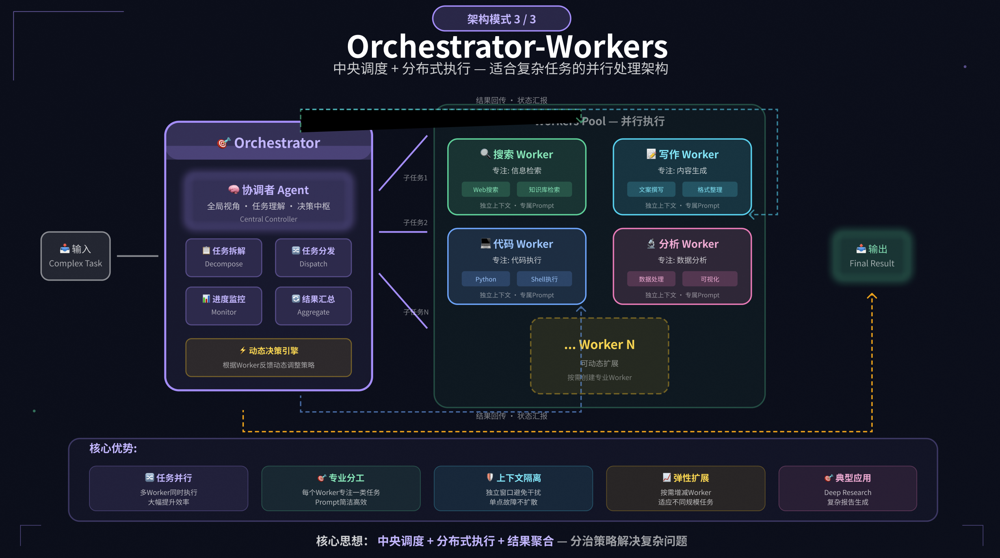

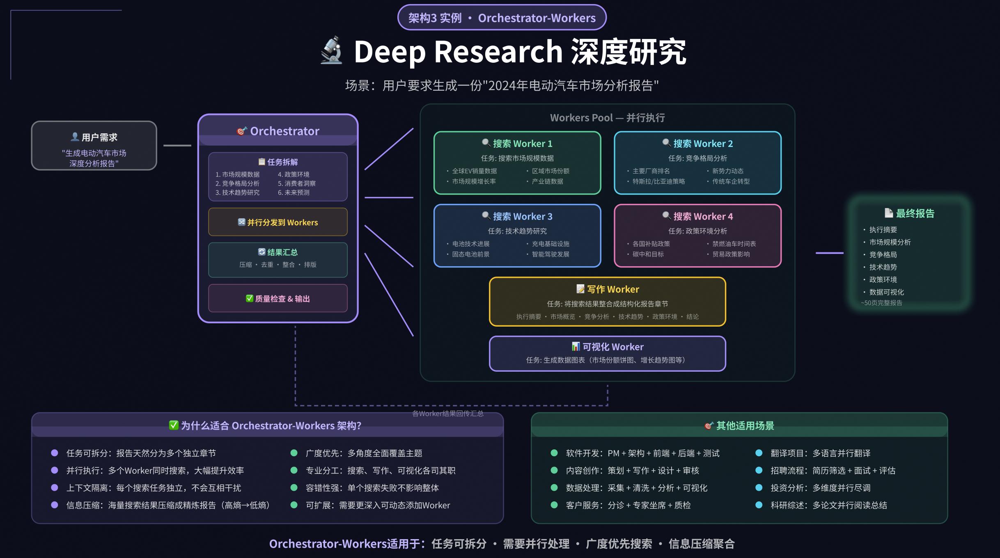

# 4.短期记忆设计

我们知道，上下文对话是以messages列表的形式传入llm，那么，这个message是怎么储存的呢

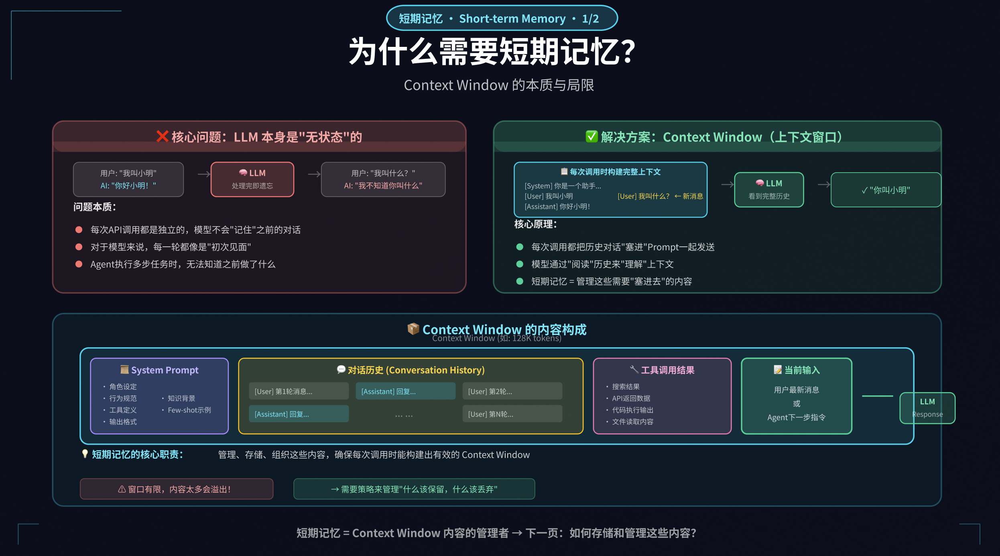

## 整体流程

```
持久化存储（MySQL/MongoDB）        Redis（工作区）
      ↓                              ↓
   长期保存所有历史                 当前活跃会话的上下文
```

### 场景一：今天新开对话

```
用户开始聊天 → 创建新 session → 对话存入 Redis → 聊完持久化到数据库
```

### 场景二：第二天继续历史对话

```
用户选择历史记录 → 从数据库加载到 Redis → 继续聊天 → 聊完更新数据库
```

## 代码示例

```python
import redis
import json

r = redis.Redis()

class ConversationMemory:
    def __init__(self, session_id):
        self.session_id = session_id
        self.redis_key = f"memory:{session_id}"
    
    def load_from_db(self, db):
        """从数据库加载历史对话到 Redis"""
        # 先检查 Redis 里有没有
        if r.exists(self.redis_key):
            return self.get_messages()
        
        # 没有就从数据库加载
        history = db.query(f"SELECT * FROM messages WHERE session_id = '{self.session_id}'")
        
        if history:
            # 加载到 Redis
            for msg in history:
                r.rpush(self.redis_key, json.dumps(msg))
            r.expire(self.redis_key, 3600)  # 1小时过期
        
        return history
    
    def add_message(self, role, content):
        """添加新消息到 Redis"""
        message = {"role": role, "content": content}
        r.rpush(self.redis_key, json.dumps(message))
        r.expire(self.redis_key, 3600)  # 刷新过期时间
        return message
    
    def get_messages(self):
        """获取当前对话上下文"""
        messages = r.lrange(self.redis_key, 0, -1)
        return [json.loads(m) for m in messages]
    
    def save_to_db(self, db):
        """持久化到数据库"""
        messages = self.get_messages()
        db.save(self.session_id, messages)
```

## 使用流程

```python
# 用户选择了一个历史会话
memory = ConversationMemory("session_abc")

# 1. 加载历史（自动判断从 Redis 还是数据库）
messages = memory.load_from_db(db)

# 2. 用户发消息
memory.add_message("user", "我们昨天聊到哪了？")

# 3. 取出上下文给 LLM
context = memory.get_messages()
response = call_llm(context)

# 4. 存入 AI 回复
memory.add_message("assistant", response)

# 5. 用户结束对话时，持久化
memory.save_to_db(db)
```

## 为什么这样设计？

| 存储 | 作用 | 特点 |
|------|------|------|
| Redis | 活跃会话的工作区 | 快、有过期机制、内存存储 |
| 数据库 | 长期保存 | 持久化、可查询历史 |

Redis 的好处是快，每次调 LLM 都要读取上下文，用 Redis 读取延迟很低。数据库负责持久化，防止数据丢失。

这就是典型的**缓存 + 持久化**的组合模式。

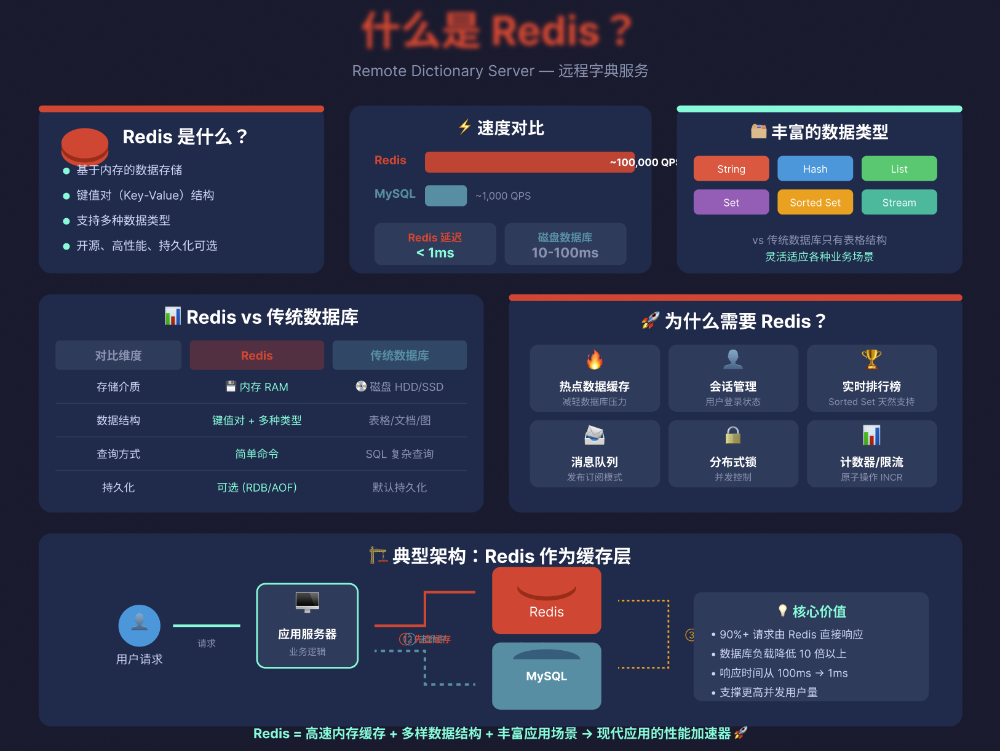

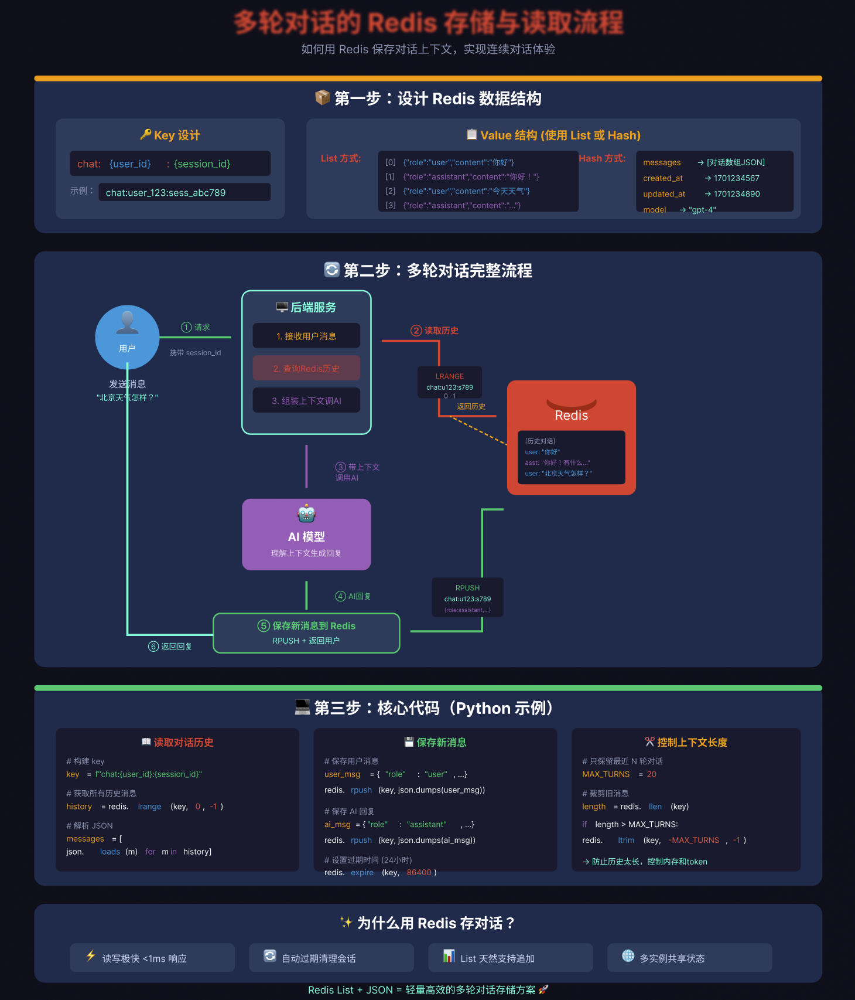

为了实现将多轮对话的上下文（Context/Messages）存储在 Redis 中，我们需要完成以下几个步骤：

1.  **连接 Redis**：使用 Python 的 `redis` 库建立连接。
2.  **序列化与反序列化**：`messages` 列表中的每个元素是字典，Redis 列表存储的是字符串（或字节），所以存入时需要 `json.dumps`，取出时需要 `json.loads`。
3.  **状态管理**：使用 `session_id` 来区分不同用户的对话历史。
4.  **操作逻辑**：每次用户提问，先存入 Redis，然后取出完整历史发给 LLM，拿到回复后，再将回复存入 Redis。

### 前置准备

你需要安装 `redis` 的 Python 库：

```bash
pip install redis
```

确保你本地或服务器上已经启动了 Redis 服务。


启动 Redis 服务取决于你的操作系统。以下是 Windows、macOS 和 Linux (Ubuntu) 三种最常见的启动方式，你可以根据你的环境选择。

---

### 方法一：Windows 系统

Windows 官方其实不原生支持 Redis，但有几种变通方法，**推荐第 1 种或第 2 种**。

#### 1. 使用 Docker（最推荐，最干净）
如果你安装了 Docker Desktop，这是最简单的方法，一行命令搞定，不污染系统。
打开 PowerShell 或 CMD，运行：
```bash
docker run -d -p 6379:6379 --name my-redis redis
```

#### 2. 下载安装包（最简单，适合新手）
微软以前维护过一个 Windows 版（虽然版本较老，但跑刚才的代码完全够用）。
1.  前往 GitHub 下载页：[MicrosoftArchive/redis/releases](https://github.com/microsoftarchive/redis/releases)
2.  下载 **`Redis-x64-3.0.504.zip`**。
3.  解压到一个文件夹。
4.  双击运行 **`redis-server.exe`**。
5.  **不要关闭这个黑窗口**，这就是 Redis 服务端。

#### 3. 使用 WSL2 (Windows Subsystem for Linux)
如果你是开发者且安装了 WSL (Ubuntu)，方法同下方的 Linux。

---

### 方法二：macOS 系统

Mac 用户通常使用 Homebrew 安装和启动。

#### 1. 如果你还没安装 Redis
打开终端（Terminal），运行：
```bash
brew install redis
```

#### 2. 启动 Redis
*   **前台启动**（测试用，窗口关了服务就停了）：
    ```bash
    redis-server &
    ```
*   **后台服务启动**（推荐，开机自启，不占终端）：
    ```bash
    brew services start redis
    ```

---

### 方法三：Linux 系统 (以 Ubuntu 为例)

#### 1. 安装
```bash
sudo apt update
sudo apt install redis-server
```

#### 2. 启动服务
通常安装后会自动启动。如果没有，运行：
```bash
sudo systemctl start redis-server
```

#### 3. 检查状态
```bash
sudo systemctl status redis-server
```

---

### 验证 Redis 是否启动成功

无论你是用哪个系统，启动后，都可以打开一个新的终端（Terminal / CMD），输入以下命令来测试：

**方式 A：如果有安装 redis-cli 工具**
```bash
redis-cli ping
```
如果返回 **`PONG`**，说明启动成功了。

**方式 B：如果没有 redis-cli，用 Python 测试**
直接运行下面的 Python 代码：
```python
import redis

try:
    r = redis.Redis(host='localhost', port=6379, db=0)
    if r.ping():
        print("✅ Redis 连接成功！服务已启动。")
except Exception as e:
    print(f"❌ 连接失败: {e}")
    print("请检查：1. redis-server 窗口是否开着？ 2. 端口是否被占用？")
```

In [ ]:
import os
import json
import redis
from openai import OpenAI
from dotenv import load_dotenv

# 加载 .env 环境变量
load_dotenv()

# 1. 初始化 Redis 连接
# 请根据实际情况修改 host, port, password
redis_client = redis.Redis(
    host='localhost',
    port=6379,
    db=0,
    decode_responses=True  # 自动解码为字符串，省去手动 decode bytes
)

# 2. 初始化 LLM 客户端
client = OpenAI(
    api_key=os.getenv("DASHSCOPE_API_KEY"),
    base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
)

class RedisChatHistory:
    def __init__(self, session_id, ttl=3600):
        """
        :param session_id: 会话唯一标识，用于区分不同用户或对话
        :param ttl: 会话过期时间（秒），默认1小时
        """
        self.session_id = f"chat_history:{session_id}"
        self.ttl = ttl

    def add_message(self, role, content):
        """添加一条消息到 Redis"""
        message = {"role": role, "content": content}
        # 将字典序列化为 JSON 字符串存入 Redis List
        # ensure_ascii=False 让 json 直接写入中文，而不是转义符
        redis_client.rpush(self.session_id, json.dumps(message, ensure_ascii=False))
        # 刷新过期时间
        redis_client.expire(self.session_id, self.ttl)

    def get_messages(self):
        """获取当前会话的所有历史消息"""
        # LRANGE key 0 -1 获取列表中所有元素
        raw_messages = redis_client.lrange(self.session_id, 0, -1)
        # 反序列化：JSON 字符串 -> 字典
        return [json.loads(msg) for msg in raw_messages]

    def clear(self):
        """清空会话历史"""
        redis_client.delete(self.session_id)
        print(">>> 会话历史已清空")

    def initialize_if_empty(self, system_prompt):
        """如果历史为空，则初始化 System Prompt"""
        if redis_client.llen(self.session_id) == 0:
            self.add_message("system", system_prompt)

# ================= 业务逻辑演示 =================

def chat_loop():
    # 模拟一个用户会话 ID
    session_id = "user_1001"
    chat_history = RedisChatHistory(session_id)

    # 1. 如果是新会话，初始化 System Prompt
    chat_history.initialize_if_empty("你是一个幽默的助手，喜欢用emoji回答问题。")

    print(f"--- 开始对话 (Session: {session_id}) ---")
    print("输入 'exit' 退出，输入 'clear' 清空记忆")

    while True:
        user_input = input("\nUser: ").strip()

        if user_input.lower() == 'exit':
            break
        
        if user_input.lower() == 'clear':
            chat_history.clear()
            # 清空后重新初始化 System Prompt
            chat_history.initialize_if_empty("你是一个幽默的助手，喜欢用emoji回答问题。")
            continue

        if not user_input:
            continue

        # 2. 将用户问题存入 Redis
        chat_history.add_message("user", user_input)

        # 3. 从 Redis 获取完整上下文 (Context)
        messages_context = chat_history.get_messages()

        try:
            # 4. 调用 LLM
            completion = client.chat.completions.create(
                model="qwen-plus",
                messages=messages_context,
                stream=False # 这里演示非流式，流式同理
            )

            # 获取回复内容
            assistant_content = completion.choices[0].message.content
            print(f"AI  : {assistant_content}")

            # 5. 将 AI 回复存入 Redis
            chat_history.add_message("assistant", assistant_content)

        except Exception as e:
            print(f"调用出错: {e}")

if __name__ == "__main__":
    # 确保 Redis 服务已开启
    try:
        redis_client.ping()
        chat_loop()
    except redis.ConnectionError:
        print("错误: 无法连接到 Redis，请检查 Redis 服务是否启动。")

--- 开始对话 (Session: user_1001) ---
输入 'exit' 退出，输入 'clear' 清空记忆



User:  你好


AI  : 你好呀！😊✨ 今天过得怎么样？希望你的一天充满小确幸和快乐～ 🌟😄



User:  过的还不错


AI  : 太棒啦！🎉 听到你过得不错，我的小表情包宇宙都开始放烟花了 🎆🎇！继续保持好状态，让快乐像Wi-Fi信号一样满格！📶💥 需要聊天、搞笑或装深沉，我随时待命～ 😎😎😎



User:  给我讲个故事


AI  : 🌙✨ 好嘞！来咯——

从前，有一只社恐的小刺猬🦔，它特别想交朋友，但每次一靠近别人，大家就：“哇！好扎！”然后跑光光……

小刺猬伤心地躲在树洞里啃苹果🍎，连松鼠都嫌它“带刺儿外卖”太危险。😭

直到有一天，森林下起了大雨🌧️，所有动物都挤在山洞避雨，可谁也不愿挨着它。

突然——⚡轰隆！一道闪电劈中大树，整片森林漆黑一片，只有小刺猬头顶的果冻夜灯💡（其实是它不小心吞了会发光的萤火虫）开始闪闪发亮✨！

“哇！移动小台灯！”🐰小兔子惊呼。

于是，小刺猬用它的“自带高光”照亮了整个山洞，还帮迷路的小鸟找到了家🐦‍⬛。

从那以后，大家再也不怕它的刺了，反而排队说：“嘿！借个光呗？”💡😄

最后——它成了森林夜间巡逻官👮♂️🌟，口号是：  
**“有我在，不怕黑，除非你怕可爱！”**

🎉 THE END 🎉  
（掌声响起来～👏👏）

怎么样？要再来一个吗？我库存管够！😉📚


### 代码逻辑解析

1.  **数据结构选择 (`RPUSH`/`LRANGE`)**：
    *   我们选择使用 Redis 的 **List** 类型来存储对话历史。
    *   `RPUSH` (Right Push)：用于在列表尾部追加新的消息（保证时间顺序）。
    *   `LRANGE 0 -1`：用于一次性读取整个列表，恢复上下文。

2.  **`RedisChatHistory` 类**：
    *   **`session_id`**：在 Redis key 前加了前缀 `chat_history:`，避免 key 冲突。
    *   **`add_message`**：在存入前使用 `json.dumps` 将 Python 字典转为字符串。同时设置 `expire`，这样用户如果长时间不说话，Redis 会自动清理旧数据，节省内存。
    *   **`get_messages`**：取出后使用 `json.loads` 还原为 LLM 需要的列表格式。

3.  **上下文拼接流程**：
    *   用户输入 -> `add_message("user", ...)` -> Redis 更新。
    *   LLM 请求前 -> `get_messages()` -> 拿到完整包含 System、之前对话、当前问题的 List。
    *   LLM 返回后 -> `add_message("assistant", ...)` -> Redis 更新。

4.  **System Prompt 处理**：
    *   代码中增加了 `initialize_if_empty` 检查。如果是第一次建立对话（Redis 中没有数据），先插入一条 System Prompt，确立人设。

## 查看Redis数据库

### 方法一：使用命令行 (redis-cli)

保持你的 Python 脚本运行，**打开一个新的终端窗口**，输入以下命令：

1.  **进入 Redis 命令行**：
    ```bash
    redis-cli
    ```

2.  **查看有哪些 Key**：
    ```bash
    KEYS *
    ```
    你会看到类似 `chat_history:user_1001` 的结果。

3.  **查看对话列表的内容**（查看 key 中的所有元素）：
    ```bash
    LRANGE chat_history:user_1001 0 -1
    ```
    *   `0` 代表列表开头。
    *   `-1` 代表列表结尾。

4.  **查看列表长度**（看存了多少条）：
    ```bash
    LLEN chat_history:user_1001
    ```

**缺点**：命令行里看到的 JSON 字符串会有很多转义符（比如 `{\"role\":\"user\"...`），比较难看。

---

### 方法二：使用可视化工具 (最推荐用于开发)

如果你不想看黑底白字的命令行，强烈建议安装一个 Redis 可视化工具。你可以一边运行 Python，一边在软件里点刷新查看。

推荐工具（任选其一）：
1.  **RedisInsight** (官方免费，功能强大)
2.  **Another Redis Desktop Manager** (开源免费，轻量级，界面简洁)

**操作步骤：**
1.  打开软件，连接 `localhost:6379`。
2.  在左侧列表中找到 `chat_history:user_1001`。
3.  点击它，右侧会直接以列表形式展示数据，点击每一行还能自动格式化 JSON，非常清晰。

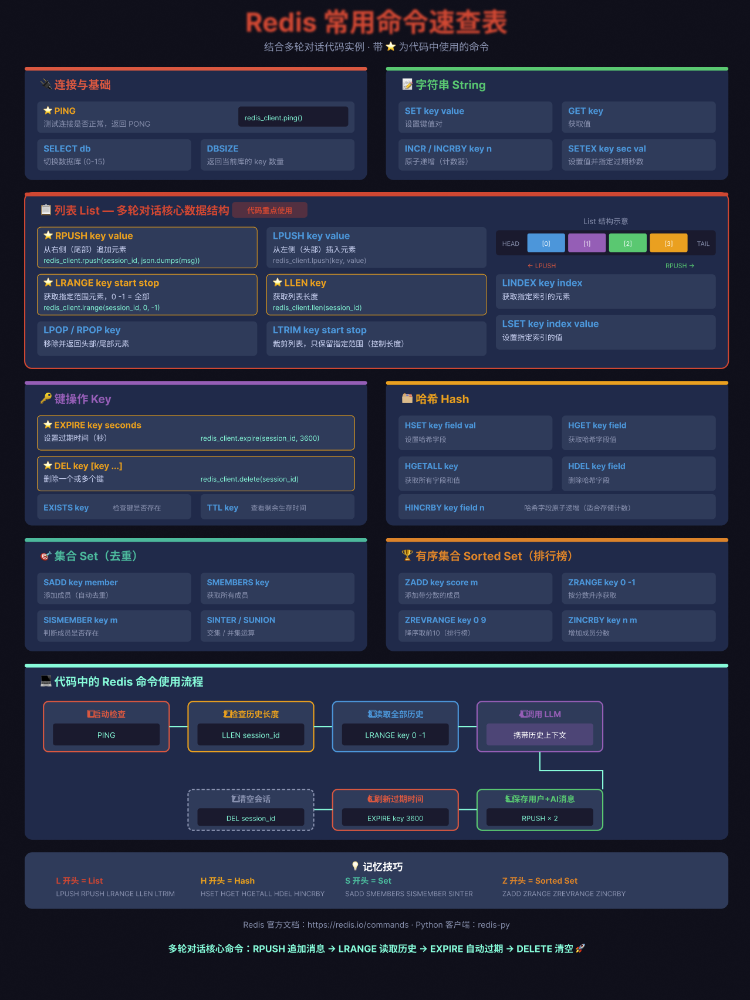

# 本章节面试重点

- Agent是什么
- 如何根据需求设计系统
- 系统怎么编排/设计（plan，组件，记忆），分别如何实现
- 有哪些工具组件
- 各个部分如何优化
  （1）如何优化跳出
  （2）如何优化plan & 工具调用
  （3）如何优化上下文
- 如何评估